In [36]:
FAST = True

In [37]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu128
GPU available: True
GPU name: Tesla T4


In [38]:
import os

for folder in ["/kaggle/input", "/tmp/498r_data"]:
    print(f"\nChecking: {folder}")

    if os.path.exists(folder):
        print(os.listdir(folder)[:20])
    else:
        print("Folder not found")


Checking: /kaggle/input
['datasets']

Checking: /tmp/498r_data
Folder not found


In [39]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    print(f"\nFolder: {root}")
    print("Subfolders:", dirs[:10])
    print("Files:", files[:10])


Folder: /kaggle/input
Subfolders: ['datasets']
Files: []

Folder: /kaggle/input/datasets
Subfolders: ['tashfianizhum']
Files: []

Folder: /kaggle/input/datasets/tashfianizhum
Subfolders: ['498r-bangla-lpr-all-in-one']
Files: []

Folder: /kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one
Subfolders: ['BanglaLPR_AllInOne_v1_1']
Files: []

Folder: /kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1
Subfolders: ['detection', 'docs', 'e2e_test', 'extras', 'ocr', 'recognition']
Files: ['README.md', 'classes_recognition.txt', 'dataset_manifest.json', 'manifest.csv', 'vocab.json']

Folder: /kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1/detection
Subfolders: ['images', 'labels']
Files: ['cond_test_blurry.txt', 'cond_test_clear.txt', 'cond_test_night.txt', 'cond_test_no_plate.txt', 'cond_test_small_plates.txt', 'conditions.json', 'data.yaml', 'data_fair_kuet.yaml', 'data_human.yaml', 'fair_kuet_test.txt']


In [40]:
from pathlib import Path

DATASET_ROOT = Path(
    "/kaggle/input/datasets/tashfianizhum/"
    "498r-bangla-lpr-all-in-one/"
    "BanglaLPR_AllInOne_v1_1"
)

DETECTION_YAML = DATASET_ROOT / "detection" / "data.yaml"

print("Dataset exists:", DATASET_ROOT.exists())
print("Detection YAML exists:", DETECTION_YAML.exists())
print("YAML path:", DETECTION_YAML)

Dataset exists: True
Detection YAML exists: True
YAML path: /kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1/detection/data.yaml


In [41]:
with open(DETECTION_YAML, "r") as f:
    print(f.read())

# path: set by the notebook to the folder that holds this file
path: .
train: images/train
val: images/val
test: images/test
nc: 1
names:
  0: "plate"



In [42]:
for split in ["train", "val", "test"]:
    image_dir = DATASET_ROOT / "detection" / "images" / split
    label_dir = DATASET_ROOT / "detection" / "labels" / split

    image_count = len(list(image_dir.glob("*")))
    label_count = len(list(label_dir.glob("*.txt")))

    print(f"{split}: Images = {image_count}, Labels = {label_count}")

train: Images = 8574, Labels = 8574
val: Images = 896, Labels = 896
test: Images = 1153, Labels = 1153


In [43]:
from pathlib import Path

DATASET_ROOT = Path(
    "/kaggle/input/datasets/tashfianizhum/"
    "498r-bangla-lpr-all-in-one/"
    "BanglaLPR_AllInOne_v1_1"
)

yaml_path = DATASET_ROOT / "detection" / "data.yaml"

print(yaml_path.read_text())

# path: set by the notebook to the folder that holds this file
path: .
train: images/train
val: images/val
test: images/test
nc: 1
names:
  0: "plate"



In [44]:
from pathlib import Path

DATASET_ROOT = Path(
    "/kaggle/input/datasets/tashfianizhum/"
    "498r-bangla-lpr-all-in-one/"
    "BanglaLPR_AllInOne_v1_1"
)

for split in ["train", "val", "test"]:
    image_dir = DATASET_ROOT / "detection" / "images" / split
    label_dir = DATASET_ROOT / "detection" / "labels" / split

    print(
        split,
        "| Images directory:", image_dir.exists(),
        "| Labels directory:", label_dir.exists()
    )

train | Images directory: True | Labels directory: True
val | Images directory: True | Labels directory: True
test | Images directory: True | Labels directory: True


In [45]:
!pip install -q ultralytics pyyaml

from pathlib import Path
import yaml
from ultralytics import YOLO

DATASET_ROOT = Path(
    "/kaggle/input/datasets/tashfianizhum/"
    "498r-bangla-lpr-all-in-one/"
    "BanglaLPR_AllInOne_v1_1"
)

DETECTION_DIR = DATASET_ROOT / "detection"

config = {
    "path": str(DETECTION_DIR),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": 1,
    "names": ["plate"]
}

yaml_path = Path("/kaggle/working/lpr_data.yaml")

with open(yaml_path, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

model = YOLO("yolov8n.pt")

results = model.train(
    data=str(yaml_path),
    epochs=10,
    imgsz=640,
    batch=16,
    device=0,
    project="/kaggle/working/lpr_training",
    name="baseline"
)

Ultralytics 8.4.189 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/lpr_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline, nbs=64, nms=None, opset=None, optimize=False, opt

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/10      2.67G      1.167     0.7471      1.204         13        640: 100% ━━━━━━━━━━━━ 536/536 6.9it/s 1:180.1sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 28/28 5.0it/s 5.6s0.2s
                   all        896        850      0.918       0.83       0.89      0.501

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/10      2.67G      1.145      0.696      1.195         11        640: 100% ━━━━━━━━━━━━ 536/536 6.9it/s 1:170.3ssss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 28/28 4.8it/s 5.8s0.2s
                   all        896        850      0.922      0.833       0.89       0.49

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/10      2.67G      1.104     0.6309      1.174         16        640: 100% ━━━━━━━━━━━━ 536/536 6.9it/s 1:180.3ssss
                 Class     I

In [46]:
from ultralytics import YOLO

best_model = YOLO(
    "/kaggle/working/lpr_training/baseline/weights/best.pt"
)

metrics = best_model.val(
    data="/kaggle/working/lpr_data.yaml",
    split="test"
)

print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP@50:", metrics.box.map50)
print("mAP@50-95:", metrics.box.map)

Ultralytics 8.4.189 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.5±0.1 ms, read: 4.4±3.3 MB/s, size: 243.2 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1/detection/labels/test... 1153 images, 160 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1153/1153 33.3it/s 34.7s0.1s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1/detection/labels is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 73/73 1.4it/s 51.4s0.2ss
                   all       1153       1011      0.958      0.947      0.965     

In [47]:
from pathlib import Path
import yaml

DATASET_ROOT = Path(
    "/kaggle/input/datasets/tashfianizhum/"
    "498r-bangla-lpr-all-in-one/"
    "BanglaLPR_AllInOne_v1_1"
)

DETECTION_DIR = DATASET_ROOT / "detection"

for split in ["train", "val", "test"]:
    img_dir = DETECTION_DIR / "images" / split
    label_dir = DETECTION_DIR / "labels" / split

    print(
        f"{split}:",
        "Images =", len(list(img_dir.glob("*"))),
        "| Labels =", len(list(label_dir.glob("*.txt")))
    )

assert DETECTION_DIR.exists(), "Detection folder not found!"

train: Images = 8574 | Labels = 8574
val: Images = 896 | Labels = 896
test: Images = 1153 | Labels = 1153


In [48]:
!pip install -q ultralytics pyyaml

from pathlib import Path
import yaml
from ultralytics import YOLO

DETECTION_DIR = Path(
    "/kaggle/input/datasets/tashfianizhum/"
    "498r-bangla-lpr-all-in-one/"
    "BanglaLPR_AllInOne_v1_1/detection"
)

config = {
    "path": str(DETECTION_DIR),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": 1,
    "names": ["plate"]
}

yaml_path = Path("/kaggle/working/lpr_data.yaml")

with open(yaml_path, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

# Load pretrained YOLOv8m
model = YOLO("yolov8m.pt")

# Train the detector
results = model.train(
    data=str(yaml_path),
    epochs=10,
    imgsz=640,
    batch=8,
    device=0,
    project="/kaggle/working/lpr_training",
    name="det_v8m_plain",
    pretrained=True
)

Ultralytics 8.4.189 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/lpr_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=det_v8m_plain, nbs=64, nms=None, opset=None, optimize=False,

In [49]:
from ultralytics import YOLO

best_model = YOLO(
    "/kaggle/working/lpr_training/"
    "det_v8m_plain/weights/best.pt"
)

metrics = best_model.val(
    data="/kaggle/working/lpr_data.yaml",
    split="test",
    conf=0.25
)

precision = metrics.box.mp
recall = metrics.box.mr
map50 = metrics.box.map50
map50_95 = metrics.box.map

print("\n===== Detection Results =====")
print(f"Precision:   {precision:.4f} ({precision * 100:.2f}%)")
print(f"Recall:      {recall:.4f} ({recall * 100:.2f}%)")
print(f"mAP@50:      {map50:.4f} ({map50 * 100:.2f}%)")
print(f"mAP@50-95:   {map50_95:.4f} ({map50_95 * 100:.2f}%)")

Ultralytics 8.4.189 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 92 layers, 25,840,339 parameters, 0 gradients, 78.7 GFLOPs
val: Fast image access ✅ (ping: 0.4±0.1 ms, read: 317.3±216.7 MB/s, size: 243.2 KB)
val: Scanning /kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1/detection/labels/test... 1153 images, 160 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1153/1153 723.3it/s 1.6s0.1s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1/detection/labels is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 73/73 3.3it/s 22.0s0.3ss
                   all       1153       1011      0.963      0.963      0.978      0.447
Speed: 0.8ms preprocess, 15.3ms inference, 0.0ms loss, 0.7ms postprocess per image
Results saved to /kaggle/working/runs/detect/val-2

===== D

In [50]:
if precision + recall > 0:
    f1 = 2 * precision * recall / (precision + recall)
else:
    f1 = 0.0

print(f"F1 Score: {f1:.4f} ({f1 * 100:.2f}%)")

F1 Score: 0.9633 (96.33%)


In [51]:
def edit_distance(reference, prediction):
    """Calculate character-level Levenshtein distance."""
    rows = len(reference) + 1
    cols = len(prediction) + 1

    dp = [[0] * cols for _ in range(rows)]

    for i in range(rows):
        dp[i][0] = i

    for j in range(cols):
        dp[0][j] = j

    for i in range(1, rows):
        for j in range(1, cols):
            cost = 0 if reference[i - 1] == prediction[j - 1] else 1

            dp[i][j] = min(
                dp[i - 1][j] + 1,
                dp[i][j - 1] + 1,
                dp[i - 1][j - 1] + cost
            )

    return dp[-1][-1]


def evaluate_ocr(ground_truths, predictions):
    assert len(ground_truths) == len(predictions)

    total_chars = 0
    total_errors = 0
    exact_matches = 0

    for gt, pred in zip(ground_truths, predictions):
        gt = str(gt).strip()
        pred = str(pred).strip()

        total_chars += len(gt)
        total_errors += edit_distance(gt, pred)

        if gt == pred:
            exact_matches += 1

    exact_plate_accuracy = (
        exact_matches / len(ground_truths) * 100
        if ground_truths else 0
    )

    cer = total_errors / total_chars if total_chars else 0

    print(f"Exact Plate Accuracy: {exact_plate_accuracy:.2f}%")
    print(f"Character Error Rate (CER): {cer:.4f}")
    print(f"CER Percentage: {cer * 100:.2f}%")

In [52]:
import os

print("PARSeq model files:")
for root, dirs, files in os.walk("/kaggle/working/parseq"):
    dirs[:] = [d for d in dirs if d not in {".git", "__pycache__"}]
    for f in files:
        if f.endswith((".ckpt", ".pt", ".pth")) or f in {"utils.py", "__init__.py"}:
            print(os.path.join(root, f))

PARSeq model files:


In [59]:

import os
import sys
import subprocess
import importlib.util
from pathlib import Path

REPO = Path("/kaggle/working/parseq")

def run(cmd):
    print("Running:", " ".join(map(str, cmd)))
    subprocess.check_call(cmd)

# 1. Locate or clone PARSeq repository
if not (REPO / "strhub").is_dir():
    if not importlib.util.find_spec("git"):
        print("Checking Git availability...")

    run([
        "git", "clone", "--depth", "1",
        "https://github.com/baudm/parseq.git",
        str(REPO)
    ])

# 2. Make repository importable
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

# 3. Install PARSeq dependencies if required
if importlib.util.find_spec("strhub") is None:
    run([
        sys.executable, "-m", "pip", "install", "-q",
        "-e", str(REPO)
    ])

# 4. Verify
from strhub.models.utils import load_from_checkpoint

print("\nSUCCESS: strhub imported successfully!")
print("Repository:", REPO)
print("PARSeq checkpoint loader is ready.")


Checking Git availability...
Running: git clone --depth 1 https://github.com/baudm/parseq.git /kaggle/working/parseq


Cloning into '/kaggle/working/parseq'...



SUCCESS: strhub imported successfully!
Repository: /kaggle/working/parseq
PARSeq checkpoint loader is ready.


In [60]:

import os

BASE = "/kaggle/working/parseq/strhub/models"

for root, dirs, files in os.walk(BASE):
    dirs[:] = [d for d in dirs if d != "__pycache__"]

    for file in files:
        if file.endswith(".py"):
            path = os.path.join(root, file)
            print(f"\n{'='*70}\nFILE: {path}\n{'='*70}")

            with open(path, "r", encoding="utf-8") as f:
                content = f.read()

            # Print class/function declarations and import statements
            for line_no, line in enumerate(content.splitlines(), start=1):
                stripped = line.strip()
                if (
                    stripped.startswith(("class ", "def ", "from ", "import "))
                    or "parseq" in stripped.lower()
                ):
                    print(f"{line_no}: {line}")



FILE: /kaggle/working/parseq/strhub/models/__init__.py

FILE: /kaggle/working/parseq/strhub/models/modules.py
2: from torch import nn
5: class BidirectionalLSTM(nn.Module):
8:     def __init__(self, input_size, hidden_size, output_size):
13:     def forward(self, input):

FILE: /kaggle/working/parseq/strhub/models/base.py
16: import math
17: from abc import ABC, abstractmethod
18: from dataclasses import dataclass
19: from typing import Optional
21: from nltk import edit_distance
23: import torch
24: import torch.nn.functional as F
25: from torch import Tensor
26: from torch.optim import Optimizer
27: from torch.optim.lr_scheduler import OneCycleLR
29: import pytorch_lightning as pl
30: from pytorch_lightning.utilities.types import STEP_OUTPUT
31: from timm.optim import create_optimizer_v2
33: from strhub.data.utils import BaseTokenizer, CharsetAdapter, CTCTokenizer, Tokenizer
37: class BatchResult:
50: class BaseSystem(pl.LightningModule, ABC):
52:     def __init__(
71:     def forwa

In [55]:

# Install missing dependency
!pip install -q lmdb

# Verify installation
import lmdb
print("lmdb installed successfully!")


lmdb installed successfully!


In [61]:

import os
from glob import glob

DATASET = (
    "/kaggle/input/datasets/tashfianizhum/"
    "498r-bangla-lpr-all-in-one/"
    "BanglaLPR_AllInOne_v1_1"
)

print("Dataset exists:", os.path.exists(DATASET))

if os.path.exists(DATASET):
    print("\nTop-level folders:")
    for item in os.listdir(DATASET):
        path = os.path.join(DATASET, item)
        print(item, "->", "Folder" if os.path.isdir(path) else "File")

    print("\nSearching for images...")
    image_paths = []
    for ext in ("*.jpg", "*.jpeg", "*.png", "*.bmp", "*.webp"):
        image_paths.extend(
            glob(os.path.join(DATASET, "**", ext), recursive=True)
        )

    print("Total images found:", len(image_paths))
    for path in image_paths[:10]:
        print(path)
else:
    print("Dataset path does not exist. Check the Kaggle input path.")


Dataset exists: True

Top-level folders:
README.md -> File
classes_recognition.txt -> File
dataset_manifest.json -> File
detection -> Folder
docs -> Folder
e2e_test -> Folder
extras -> Folder
manifest.csv -> File
ocr -> Folder
recognition -> Folder
vocab.json -> File

Searching for images...
Total images found: 38016
/kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1/detection/images/test/kuet_003d2b1ed410.jpg
/kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1/detection/images/test/kuet_008c83a3c669.jpg
/kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1/detection/images/test/kuet_01ee4abceabb.jpg
/kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1/detection/images/test/kuet_02cb47e2fcef.jpg
/kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1/detection/images/test/kuet_03039ecf2c4f.jpg
/kaggle/input/dataset

In [62]:

# ============================================================
# YOLO + PARSeq | Bangladeshi License Plate Recognition
# ============================================================

import os
import glob
import torch
import cv2
import pandas as pd
from PIL import Image
from ultralytics import YOLO
from strhub.models.utils import load_from_checkpoint
from strhub.data.module import SceneTextDataModule

# ---------------- PATHS ----------------
DATASET = (
    "/kaggle/input/datasets/tashfianizhum/"
    "498r-bangla-lpr-all-in-one/"
    "BanglaLPR_AllInOne_v1_1"
)

DETECTOR_PATH = (
    "/kaggle/working/lpr_training/"
    "det_v8m_plain/weights/best.pt"
)

IMAGE_DIR = os.path.join(DATASET, "detection", "images", "test")
OUTPUT_DIR = "/kaggle/working/parseq_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

OUTPUT_CSV = os.path.join(OUTPUT_DIR, "recognition_results.csv")
OUTPUT_IMAGE = os.path.join(OUTPUT_DIR, "prediction.jpg")

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

# ---------------- FIND TEST IMAGE ----------------
extensions = ["*.jpg", "*.jpeg", "*.png", "*.bmp", "*.webp"]
image_paths = []

for ext in extensions:
    image_paths.extend(glob.glob(os.path.join(IMAGE_DIR, ext)))

if not image_paths:
    raise FileNotFoundError(f"No images found in {IMAGE_DIR}")

image_path = image_paths[0]
print("Test image:", image_path)

# ---------------- LOAD YOLO ----------------
if not os.path.isfile(DETECTOR_PATH):
    raise FileNotFoundError(f"YOLO weights not found: {DETECTOR_PATH}")

detector = YOLO(DETECTOR_PATH)
print("YOLO loaded successfully.")

# ---------------- LOAD PARSEQ ----------------
# Downloads official pretrained weights if internet is enabled.
# Generic pretrained PARSeq is not Bangla-plate-specific.
recognizer = load_from_checkpoint("pretrained=parseq")
recognizer.eval().to(device)

transform = SceneTextDataModule.get_transform(
    recognizer.hparams.img_size
)

print("PARSeq loaded successfully.")

# ---------------- RUN DETECTION ----------------
image = cv2.imread(image_path)

if image is None:
    raise ValueError("Could not read test image.")

results = detector.predict(
    source=image,
    conf=0.25,
    verbose=False
)

rows = []

for result in results:
    if result.boxes is None or len(result.boxes) == 0:
        print("No plate detected in this image.")
        continue

    for i, box in enumerate(result.boxes):
        x1, y1, x2, y2 = map(
            int, box.xyxy[0].detach().cpu().tolist()
        )

        h, w = image.shape[:2]
        x1, y1 = max(0, x1), max(0, y1)
        x2, y2 = min(w, x2), min(h, y2)

        crop = image[y1:y2, x1:x2]

        if crop.size == 0:
            continue

        # Convert plate crop BGR -> RGB
        crop_rgb = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
        pil_crop = Image.fromarray(crop_rgb)
        input_tensor = transform(pil_crop).unsqueeze(0).to(device)

        # PARSeq inference
        with torch.inference_mode():
            logits = recognizer(input_tensor)
            probabilities = logits.softmax(-1)
            decoded = recognizer.tokenizer.decode(probabilities)

        predicted_text = decoded[0][0]
        detection_confidence = float(
            box.conf[0].detach().cpu()
        )

        rows.append({
            "image": os.path.basename(image_path),
            "predicted_plate_text": predicted_text,
            "detection_confidence": detection_confidence,
            "x1": x1,
            "y1": y1,
            "x2": x2,
            "y2": y2
        })

        cv2.rectangle(
            image, (x1, y1), (x2, y2), (0, 255, 0), 2
        )
        cv2.putText(
            image,
            str(predicted_text),
            (x1, max(25, y1 - 10)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (0, 255, 0),
            2
        )

        print(f"Plate {i + 1}: {predicted_text}")
        print(f"Detection confidence: {detection_confidence:.4f}")

# ---------------- SAVE OUTPUTS ----------------
if rows:
    df = pd.DataFrame(rows)
    df.to_csv(OUTPUT_CSV, index=False)
    cv2.imwrite(OUTPUT_IMAGE, image)

    print("\nSaved CSV:", OUTPUT_CSV)
    print("Saved annotated image:", OUTPUT_IMAGE)
    display(df)
    display(Image.open(OUTPUT_IMAGE))
else:
    print("No plate crops were generated. Try another test image.")


Device: cuda
Test image: /kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1/detection/images/test/kuet_003d2b1ed410.jpg
YOLO loaded successfully.
Downloading: "https://github.com/baudm/parseq/releases/download/v1.0.0/parseq-bb5792a6.pt" to /root/.cache/torch/hub/checkpoints/parseq-bb5792a6.pt


100%|██████████| 91.0M/91.0M [00:00<00:00, 205MB/s]


PARSeq loaded successfully.
No plate detected in this image.
No plate crops were generated. Try another test image.


Total test images: 1153
Scanning up to 100 images with confidence threshold 0.10...
First successful image: /kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1/detection/images/test/kuet_008c83a3c669.jpg

Detected plates: 1
CSV saved: /kaggle/working/parseq_results/recognition_results.csv
Annotated image saved: /kaggle/working/parseq_results/prediction.jpg


,image,predicted_text,detection_confidence,x1,y1,x2,y2
0,kuet_008c83a3c669.jpg,ES,0.124981,271,681,290,703


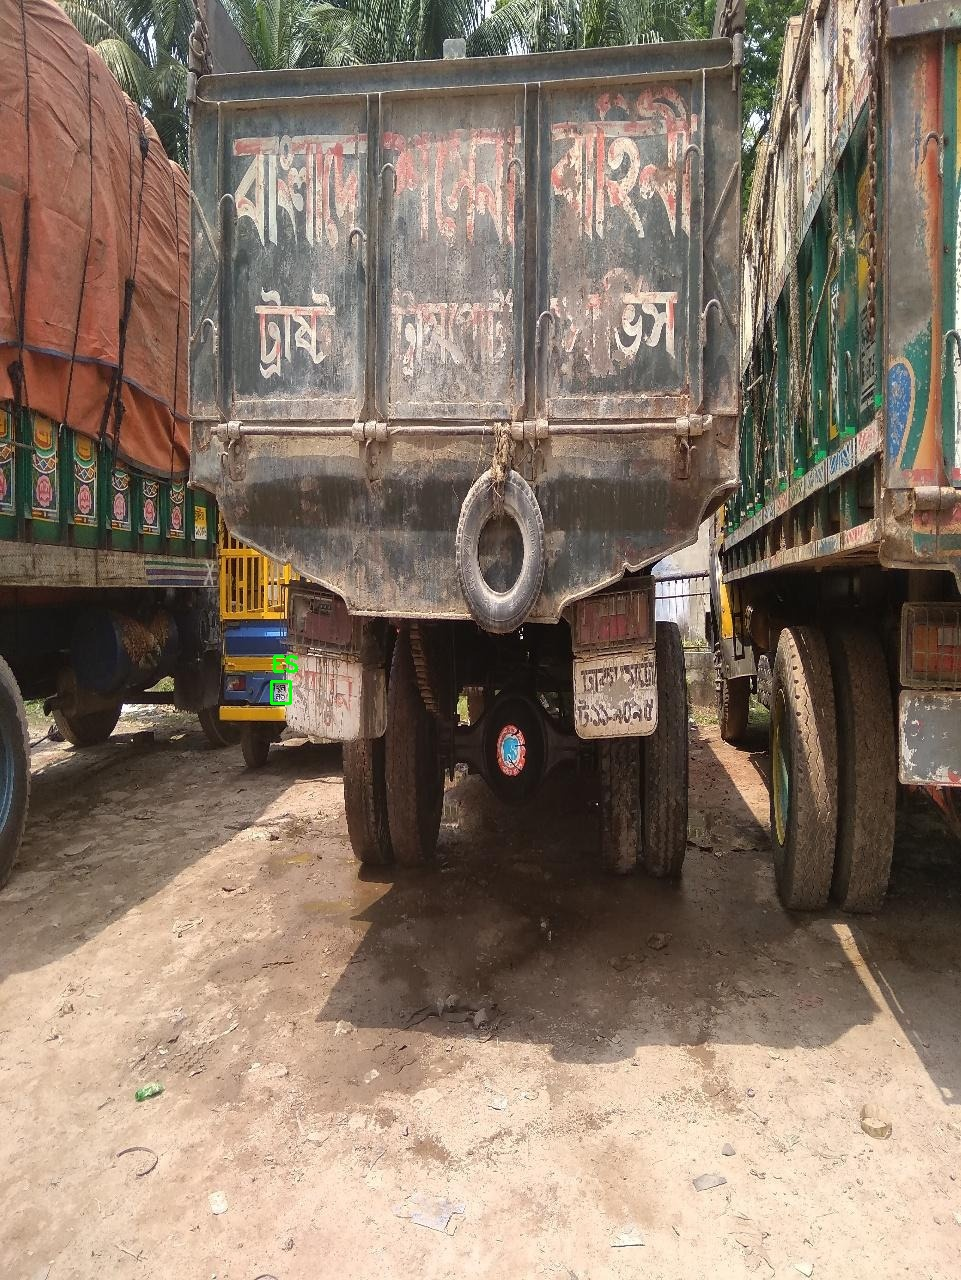

In [63]:

import os, glob, cv2, torch
import pandas as pd
from PIL import Image
from IPython.display import display

# Dataset paths
DATASET = "/kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1"
IMAGE_DIR = os.path.join(DATASET, "detection", "images", "test")
OUT_DIR = "/kaggle/working/parseq_results"
os.makedirs(OUT_DIR, exist_ok=True)

# Find test images
image_paths = []
for ext in ("*.jpg", "*.jpeg", "*.png", "*.webp"):
    image_paths += glob.glob(os.path.join(IMAGE_DIR, ext))

if not image_paths:
    raise FileNotFoundError(f"No test images found in {IMAGE_DIR}")

print("Total test images:", len(image_paths))
print("Scanning up to 100 images with confidence threshold 0.10...")

rows = []
found_image = None

# Scan multiple images instead of only the first one
for image_path in image_paths[:100]:
    image = cv2.imread(image_path)
    if image is None:
        continue

    results = detector.predict(
        source=image,
        conf=0.10,
        iou=0.50,
        imgsz=1280,
        verbose=False
    )

    for result in results:
        if result.boxes is None or len(result.boxes) == 0:
            continue

        for i, box in enumerate(result.boxes):
            x1, y1, x2, y2 = map(
                int, box.xyxy[0].detach().cpu().tolist()
            )

            h, w = image.shape[:2]
            x1, y1 = max(0, x1), max(0, y1)
            x2, y2 = min(w, x2), min(h, y2)

            crop = image[y1:y2, x1:x2]
            if crop.size == 0:
                continue

            # PARSeq recognition
            rgb = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
            pil_crop = Image.fromarray(rgb)
            tensor = transform(pil_crop).unsqueeze(0).to(device)

            with torch.inference_mode():
                logits = recognizer(tensor)
                probs = logits.softmax(-1)
                decoded = recognizer.tokenizer.decode(probs)

            text = decoded[0][0]
            conf = float(box.conf[0].detach().cpu())

            rows.append({
                "image": os.path.basename(image_path),
                "predicted_text": text,
                "detection_confidence": conf,
                "x1": x1, "y1": y1, "x2": x2, "y2": y2
            })

            # Annotate the first successful image
            if found_image is None:
                found_image = image.copy()

            cv2.rectangle(
                image, (x1, y1), (x2, y2), (0, 255, 0), 2
            )
            cv2.putText(
                image, str(text), (x1, max(y1 - 10, 25)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2
            )

            if found_image is not None and len(rows) == 1:
                found_image = image.copy()

    # Stop after finding at least one plate
    if rows:
        print("First successful image:", image_path)
        break

if rows:
    df = pd.DataFrame(rows)
    csv_path = os.path.join(OUT_DIR, "recognition_results.csv")
    img_path = os.path.join(OUT_DIR, "prediction.jpg")

    df.to_csv(csv_path, index=False)
    cv2.imwrite(img_path, image)

    print("\nDetected plates:", len(rows))
    print("CSV saved:", csv_path)
    print("Annotated image saved:", img_path)
    display(df)
    display(Image.open(img_path))
else:
    print("\nNo plates detected in the first 100 images.")
    print("Next: check the detector's validation results and dataset labels.")


Box 1: x1=271, y1=681, x2=290, y2=703, confidence=0.1250
Box 2: x1=566, y1=664, x2=667, y2=746, confidence=0.0731
Box 3: x1=423, y1=701, x2=437, y2=710, confidence=0.0639
Box 4: x1=110, y1=468, x2=130, y2=492, confidence=0.0252
Box 5: x1=422, y1=698, x2=436, y2=709, confidence=0.0179


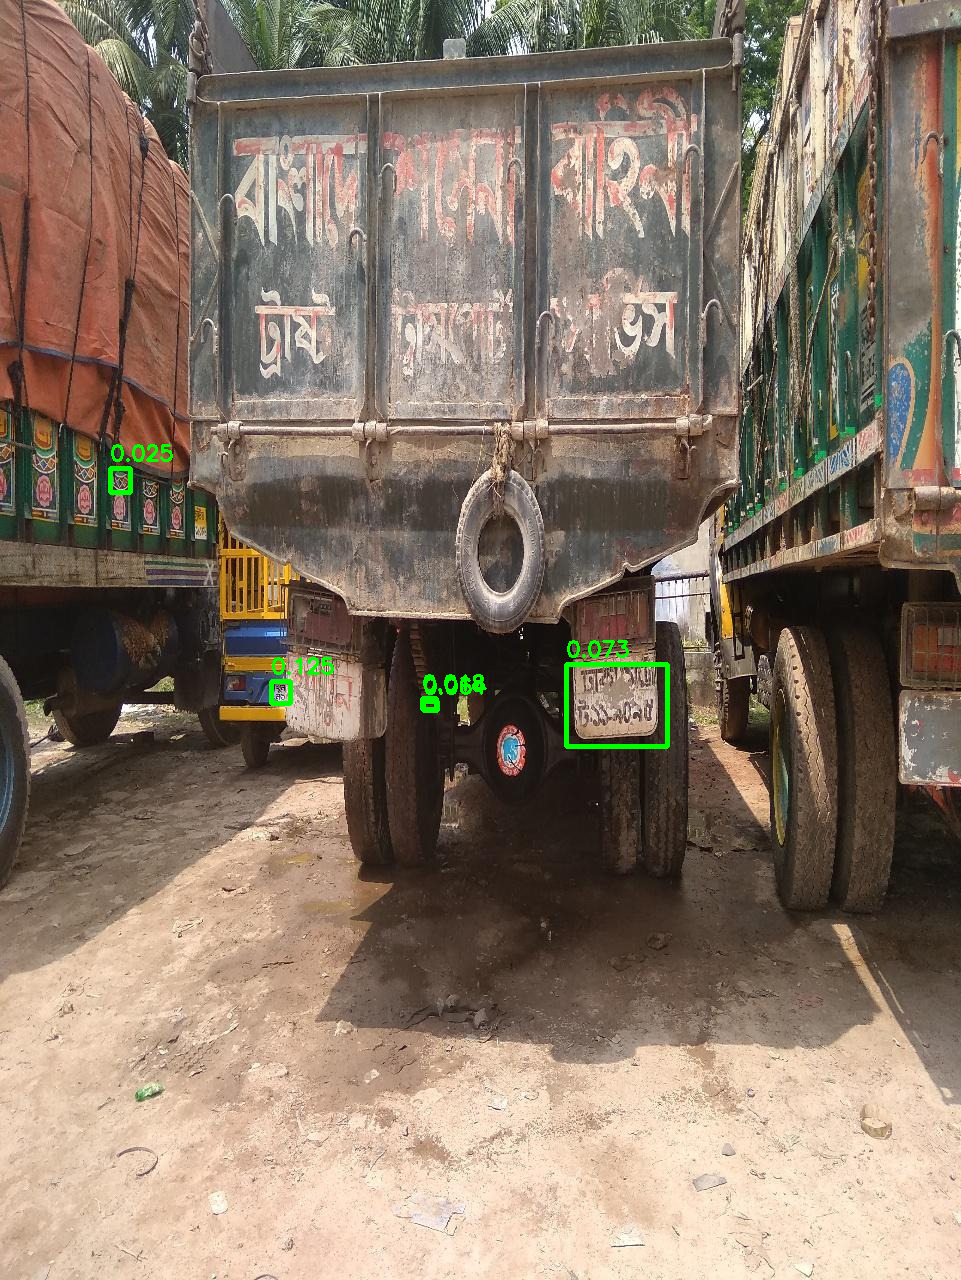

In [64]:

import os
import cv2
import matplotlib.pyplot as plt
from IPython.display import display
from PIL import Image

DATASET = "/kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1"
IMAGE_PATH = os.path.join(
    DATASET, "detection", "images", "test",
    "kuet_008c83a3c669.jpg"
)

image = cv2.imread(IMAGE_PATH)
if image is None:
    raise FileNotFoundError(IMAGE_PATH)

# Run detector with a lower threshold for inspection
result = detector.predict(
    source=image,
    conf=0.01,
    imgsz=1280,
    verbose=False
)[0]

annotated = image.copy()

if result.boxes is not None and len(result.boxes):
    for i, box in enumerate(result.boxes):
        x1, y1, x2, y2 = map(
            int, box.xyxy[0].detach().cpu().tolist()
        )
        conf = float(box.conf[0].detach().cpu())

        cv2.rectangle(
            annotated, (x1, y1), (x2, y2), (0, 255, 0), 3
        )
        cv2.putText(
            annotated, f"{conf:.3f}",
            (x1, max(y1 - 8, 20)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2
        )

        print(
            f"Box {i+1}: x1={x1}, y1={y1}, "
            f"x2={x2}, y2={y2}, confidence={conf:.4f}"
        )

    display(Image.fromarray(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)))
else:
    print("No detections at confidence 0.01.")


Original image size: 961 x 1280
Number of detected boxes: 4
Box 1: x1=271, y1=681, x2=290, y2=703, width=19, height=22, confidence=0.1250
Box 2: x1=566, y1=664, x2=667, y2=746, width=101, height=82, confidence=0.0731
Box 3: x1=423, y1=701, x2=437, y2=710, width=14, height=9, confidence=0.0639
Box 4: x1=110, y1=468, x2=130, y2=492, width=20, height=24, confidence=0.0252


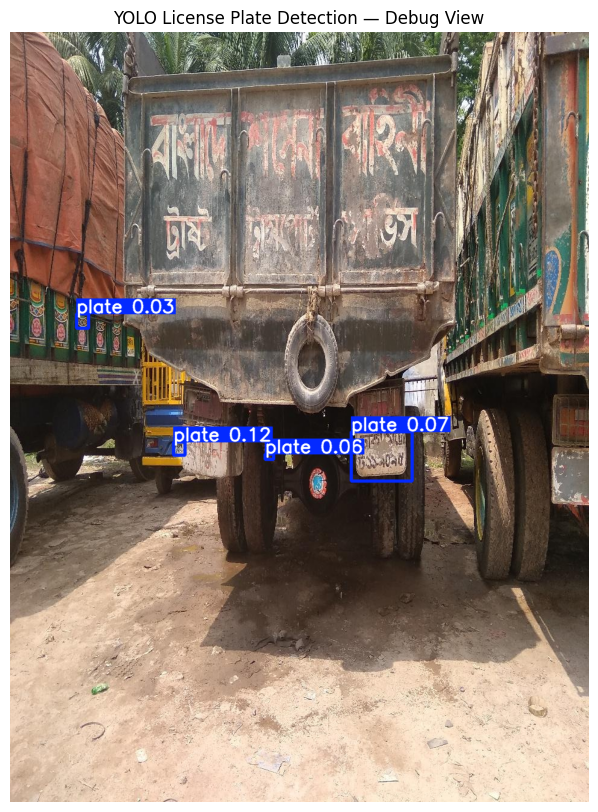

In [65]:

from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

# Load trained detector
model = YOLO(
    "/kaggle/working/lpr_training/det_v8m_plain/weights/best.pt"
)

# Test image
img_path = (
    "/kaggle/input/datasets/tashfianizhum/"
    "498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1/"
    "detection/images/test/kuet_008c83a3c669.jpg"
)

img = cv2.imread(img_path)

if img is None:
    raise FileNotFoundError(f"Image not found: {img_path}")

# Run detection with a low threshold for debugging
results = model.predict(
    source=img,
    conf=0.01,
    imgsz=1280,
    iou=0.5,
    verbose=False
)

result = results[0]

print("Original image size:", img.shape[1], "x", img.shape[0])
print("Number of detected boxes:", len(result.boxes))

for i, box in enumerate(result.boxes, 1):
    x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
    conf = float(box.conf[0])

    print(
        f"Box {i}: x1={x1}, y1={y1}, "
        f"x2={x2}, y2={y2}, "
        f"width={x2-x1}, height={y2-y1}, "
        f"confidence={conf:.4f}"
    )

# Visualize detections
annotated = result.plot()
annotated = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(14, 10))
plt.imshow(annotated)
plt.axis("off")
plt.title("YOLO License Plate Detection — Debug View")
plt.show()


In [66]:

from pathlib import Path
import yaml

ROOT = Path(
    "/kaggle/input/datasets/tashfianizhum/"
    "498r-bangla-lpr-all-in-one/"
    "BanglaLPR_AllInOne_v1_1"
)

# 1. Read detection configuration
yaml_path = ROOT / "detection" / "data.yaml"

print("YAML exists:", yaml_path.exists())

if yaml_path.exists():
    with open(yaml_path, "r") as f:
        config = yaml.safe_load(f)

    print("\n--- detection/data.yaml ---")
    print(config)

# 2. Check dataset folders
for folder in [
    ROOT / "detection" / "images" / "train",
    ROOT / "detection" / "images" / "val",
    ROOT / "detection" / "images" / "test",
    ROOT / "detection" / "labels" / "train",
    ROOT / "detection" / "labels" / "val",
    ROOT / "detection" / "labels" / "test",
]:
    print(f"{folder}: exists={folder.exists()}")

# 3. Find labels associated with the test image
image_name = "kuet_008c83a3c669"

print("\n--- Matching label files ---")

for label_path in ROOT.rglob(image_name + ".txt"):
    print("\nLabel file:", label_path)
    print(label_path.read_text()[:3000])

# 4. Show a sample of training label files
print("\n--- Sample training labels ---")

train_labels = ROOT / "detection" / "labels" / "train"

if train_labels.exists():
    files = list(train_labels.glob("*.txt"))[:3]

    for file in files:
        print(f"\n{file.name}")
        print(file.read_text()[:1000])
else:
    print("Training labels folder not found at the expected path.")


YAML exists: True

--- detection/data.yaml ---
{'path': '.', 'train': 'images/train', 'val': 'images/val', 'test': 'images/test', 'nc': 1, 'names': {0: 'plate'}}
/kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1/detection/images/train: exists=True
/kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1/detection/images/val: exists=True
/kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1/detection/images/test: exists=True
/kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1/detection/labels/train: exists=True
/kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1/detection/labels/val: exists=True
/kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1/detection/labels/test: exists=True

--- Matching label files ---

Label file: /kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-

Model classes: {0: 'plate'}
Ground-truth label: 0 0.640479 0.544531 0.123829 0.087500

Predicted boxes: 5


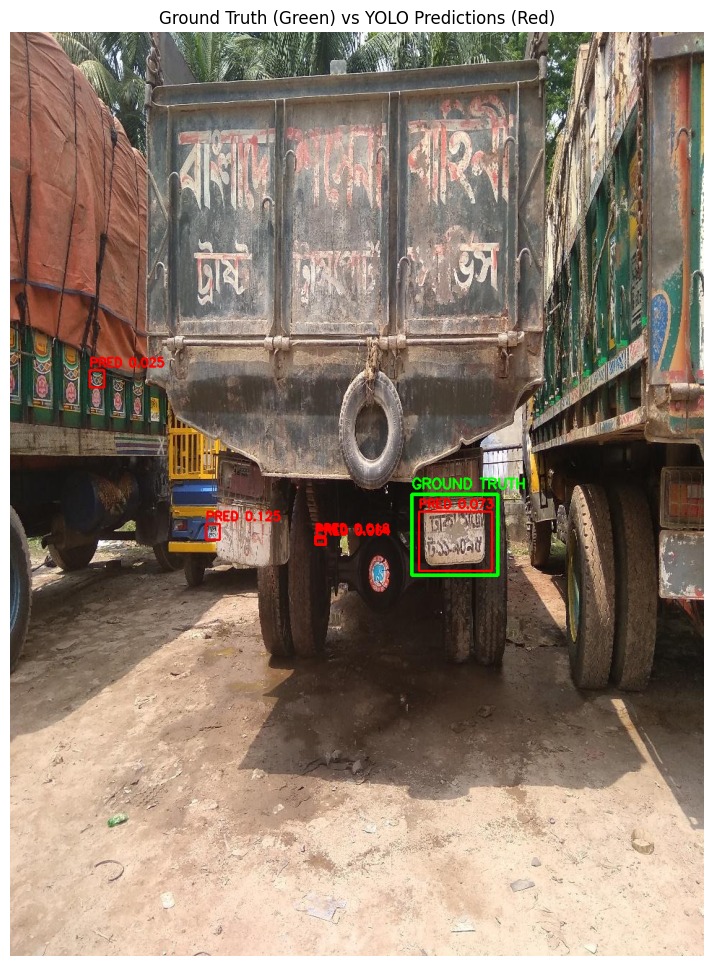

In [67]:

from pathlib import Path
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

ROOT = Path(
    "/kaggle/input/datasets/tashfianizhum/"
    "498r-bangla-lpr-all-in-one/"
    "BanglaLPR_AllInOne_v1_1"
)

img_path = ROOT / "detection/images/test/kuet_008c83a3c669.jpg"
label_path = ROOT / "detection/labels/test/kuet_008c83a3c669.txt"

model = YOLO(
    "/kaggle/working/lpr_training/det_v8m_plain/weights/best.pt"
)

img = cv2.imread(str(img_path))
if img is None:
    raise FileNotFoundError(img_path)

H, W = img.shape[:2]
vis = img.copy()

# Draw ground-truth boxes in GREEN
for line in label_path.read_text().strip().splitlines():
    values = list(map(float, line.split()))
    cls, cx, cy, bw, bh = values

    x1 = int((cx - bw / 2) * W)
    y1 = int((cy - bh / 2) * H)
    x2 = int((cx + bw / 2) * W)
    y2 = int((cy + bh / 2) * H)

    cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 255, 0), 3)
    cv2.putText(
        vis, "GROUND TRUTH",
        (x1, max(25, y1 - 8)),
        cv2.FONT_HERSHEY_SIMPLEX, 0.65, (0, 255, 0), 2
    )

# Draw model predictions in RED
result = model.predict(
    source=img,
    conf=0.01,
    imgsz=1280,
    verbose=False
)[0]

for box in result.boxes:
    x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
    conf = float(box.conf[0])

    cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 0, 255), 2)
    cv2.putText(
        vis, f"PRED {conf:.3f}",
        (x1, max(20, y1 - 5)),
        cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 0, 255), 2
    )

print("Model classes:", model.names)
print("Ground-truth label:", label_path.read_text())
print("Predicted boxes:", len(result.boxes))

plt.figure(figsize=(10, 12))
plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
plt.title("Ground Truth (Green) vs YOLO Predictions (Red)")
plt.axis("off")
plt.show()


In [68]:
from pathlib import Path
from ultralytics import YOLO
import pandas as pd
import json
import time

DATA_YAML = (
    "/kaggle/input/datasets/tashfianizhum/"
    "498r-bangla-lpr-all-in-one/"
    "BanglaLPR_AllInOne_v1_1/detection/data.yaml"
)

SEARCH_DIRS = [
    Path("/kaggle/working"),
    Path("/kaggle/input")
]

# Find trained model weights
model_files = []

for root in SEARCH_DIRS:
    if root.exists():
        model_files.extend(root.rglob("best.pt"))

# Remove duplicate paths
model_files = sorted(set(model_files))

if not model_files:
    raise FileNotFoundError(
        "No best.pt files found. Train models first or check the model path."
    )

print(f"Models found: {len(model_files)}")

results = []

for model_path in model_files:
    print(f"\nEvaluating: {model_path}")

    try:
        model = YOLO(str(model_path))

        start = time.time()

        metrics = model.val(
            data=DATA_YAML,
            split="test",
            imgsz=640,
            plots=False,
            verbose=False
        )

        eval_time = time.time() - start

        params = sum(
            p.numel() for p in model.model.parameters()
        )

        results.append({
            "Model": model_path.parent.parent.name,
            "Weights": str(model_path),
            "Precision": float(metrics.box.mp),
            "Recall": float(metrics.box.mr),
            "mAP50": float(metrics.box.map50),
            "mAP50-95": float(metrics.box.map),
            "Parameters_M": round(params / 1e6, 3),
            "Size_MB": round(
                model_path.stat().st_size / (1024 ** 2), 3
            ),
            "Evaluation_Time_s": round(eval_time, 2),
            "Status": "Success"
        })

    except Exception as e:
        print(f"Evaluation failed: {e}")

        results.append({
            "Model": model_path.parent.parent.name,
            "Weights": str(model_path),
            "Status": f"Failed: {str(e)[:150]}"
        })

df = pd.DataFrame(results)

successful = df[df["Status"] == "Success"].copy()

if not successful.empty:
    successful = successful.sort_values(
        by="mAP50-95",
        ascending=False
    ).reset_index(drop=True)

    successful.insert(
        0, "Rank", range(1, len(successful) + 1)
    )

    print("\nMODEL COMPARISON")
    display(successful)

    best_model = successful.iloc[0]

    print("\nBEST MODEL")
    print("Model:", best_model["Model"])
    print("Weights:", best_model["Weights"])
    print(f"Precision: {best_model['Precision']:.4f}")
    print(f"Recall: {best_model['Recall']:.4f}")
    print(f"mAP50: {best_model['mAP50']:.4f}")
    print(f"mAP50-95: {best_model['mAP50-95']:.4f}")

    successful.to_csv(
        "/kaggle/working/model_comparison.csv",
        index=False
    )

    with open(
        "/kaggle/working/best_model_summary.json", "w"
    ) as f:
        json.dump(
            best_model.to_dict(),
            f,
            indent=4,
            default=str
        )

    print("\nSaved:")
    print("/kaggle/working/model_comparison.csv")
    print("/kaggle/working/best_model_summary.json")

else:
    print("No models were evaluated successfully.")

if len(df) > len(successful):
    print("\nFAILED MODELS")
    display(df[df["Status"] != "Success"])

Models found: 2

Evaluating: /kaggle/working/lpr_training/baseline/weights/best.pt
Ultralytics 8.4.189 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs

Evaluation failed: Dataset '/kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1/detection/data.yaml' images not found, missing path '/kaggle/working/images/test'
Note dataset download directory is '/kaggle/working/datasets'. You can update this in '/root/.config/Ultralytics/settings.json'

Evaluating: /kaggle/working/lpr_training/det_v8m_plain/weights/best.pt
Ultralytics 8.4.189 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 92 layers, 25,840,339 parameters, 0 gradients, 78.7 GFLOPs

Evaluation failed: Dataset '/kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1/detection/data.yaml' images not found, missing path '/kaggle/working/im

,Model,Weights,Status
0,baseline,/kaggle/working/lpr_training/baseline/weights/...,Failed: Dataset '/kaggle/input/datasets/tashfi...
1,det_v8m_plain,/kaggle/working/lpr_training/det_v8m_plain/wei...,Failed: Dataset '/kaggle/input/datasets/tashfi...


In [69]:
from pathlib import Path
import yaml

YAML_PATH = Path(
    "/kaggle/input/datasets/tashfianizhum/"
    "498r-bangla-lpr-all-in-one/"
    "BanglaLPR_AllInOne_v1_1/detection/data.yaml"
)

DATASET_ROOT = YAML_PATH.parent
FIXED_YAML = Path("/kaggle/working/fixed_data.yaml")

with open(YAML_PATH, "r") as f:
    config = yaml.safe_load(f)

config["path"] = str(DATASET_ROOT)

for split in ["train", "val", "test"]:
    value = config.get(split)

    if value is None:
        continue

    values = value if isinstance(value, list) else [value]
    resolved_values = []

    for item in values:
        p = Path(item)

        if not p.is_absolute():
            p = DATASET_ROOT / p

        resolved_values.append(str(p.resolve()))

    config[split] = (
        resolved_values if isinstance(value, list)
        else resolved_values[0]
    )

with open(FIXED_YAML, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print("Fixed YAML:", FIXED_YAML)
print("\nResolved configuration:")

for split in ["train", "val", "test"]:
    value = config.get(split)

    if value is None:
        continue

    paths = value if isinstance(value, list) else [value]

    for p in paths:
        print(f"{split}: {p} | Exists: {Path(p).exists()}")

Fixed YAML: /kaggle/working/fixed_data.yaml

Resolved configuration:
train: /kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1/detection/images/train | Exists: True
val: /kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1/detection/images/val | Exists: True
test: /kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1/detection/images/test | Exists: True


In [70]:
from pathlib import Path
from ultralytics import YOLO
import pandas as pd

DATA_YAML = "/kaggle/working/fixed_data.yaml"

MODEL_DIR = Path("/kaggle/working/lpr_training")

model_files = sorted(MODEL_DIR.rglob("best.pt"))
results = []

for model_path in model_files:
    print(f"\nEvaluating: {model_path}")

    try:
        model = YOLO(str(model_path))

        metrics = model.val(
            data=DATA_YAML,
            split="test",
            imgsz=640,
            plots=False,
            verbose=False
        )

        results.append({
            "Model": model_path.parent.parent.name,
            "Weights": str(model_path),
            "Precision": float(metrics.box.mp),
            "Recall": float(metrics.box.mr),
            "mAP50": float(metrics.box.map50),
            "mAP50-95": float(metrics.box.map)
        })

    except Exception as e:
        print("Evaluation failed:", e)

if results:
    df = pd.DataFrame(results)
    df = df.sort_values("mAP50-95", ascending=False)
    df.insert(0, "Rank", range(1, len(df) + 1))

    display(df)

    df.to_csv(
        "/kaggle/working/model_comparison.csv",
        index=False
    )

    print("Saved: /kaggle/working/model_comparison.csv")
    print("\nBest model:")
    display(df.iloc[[0]])
else:
    print("No models evaluated. Check the split paths printed in Cell 1.")


Evaluating: /kaggle/working/lpr_training/baseline/weights/best.pt
Ultralytics 8.4.189 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.4±0.1 ms, read: 265.9±174.3 MB/s, size: 194.6 KB)
val: Scanning /kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1/detection/labels/test... 1153 images, 160 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1153/1153 661.8it/s 1.7s0.0s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1/detection/labels is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 73/73 8.2it/s 8.9s0.1s
                   all       1153       1011      0.958      0.947      0.965      0.445
Speed: 0.7ms preprocess, 2.7ms inference, 0.0ms loss, 1.1ms postprocess per ima

,Rank,Model,Weights,Precision,Recall,mAP50,mAP50-95
1,1,det_v8m_plain,/kaggle/working/lpr_training/det_v8m_plain/wei...,0.963263,0.963403,0.98514,0.453898
0,2,baseline,/kaggle/working/lpr_training/baseline/weights/...,0.957964,0.946732,0.96497,0.444579


Saved: /kaggle/working/model_comparison.csv

Best model:


,Rank,Model,Weights,Precision,Recall,mAP50,mAP50-95
1,1,det_v8m_plain,/kaggle/working/lpr_training/det_v8m_plain/wei...,0.963263,0.963403,0.98514,0.453898


In [71]:
from pathlib import Path

ROOT = Path(
    "/kaggle/input/datasets/tashfianizhum/"
    "498r-bangla-lpr-all-in-one/"
    "BanglaLPR_AllInOne_v1_1"
)

print("DATASET ROOT:", ROOT)
print("ROOT EXISTS:", ROOT.exists())

for folder in sorted(ROOT.rglob("*")):
    if folder.is_dir():
        files = list(folder.iterdir())
        image_count = sum(
            p.is_file() and p.suffix.lower() in
            {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
            for p in files
        )
        annotation_files = [
            p.name for p in files
            if p.is_file() and p.suffix.lower()
            in {".csv", ".json", ".txt", ".tsv"}
        ]

        if image_count or annotation_files:
            print(
                f"{folder} | images={image_count} "
                f"| annotations={annotation_files[:10]}"
            )

DATASET ROOT: /kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1
ROOT EXISTS: True
/kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1/detection | images=0 | annotations=['cond_test_blurry.txt', 'cond_test_clear.txt', 'cond_test_night.txt', 'cond_test_no_plate.txt', 'cond_test_small_plates.txt', 'conditions.json', 'fair_kuet_test.txt', 'fair_kuet_train.txt', 'fair_kuet_val.txt', 'train_human.txt']
/kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1/detection/images/test | images=1153 | annotations=[]
/kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1/detection/images/test_fog_synth | images=1153 | annotations=[]
/kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1/detection/images/test_rain_synth | images=1153 | annotations=[]
/kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne

In [72]:
from pathlib import Path
import pandas as pd

ROOT = Path(
    "/kaggle/input/datasets/tashfianizhum/"
    "498r-bangla-lpr-all-in-one/"
    "BanglaLPR_AllInOne_v1_1/ocr"
)

for split in ["train", "val", "test"]:
    csv_path = ROOT / f"{split}.csv"

    print(f"\n{'=' * 60}")
    print(f"{split.upper()} CSV")
    print("Path:", csv_path)
    print("Exists:", csv_path.exists())

    if csv_path.exists():
        df = pd.read_csv(csv_path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        display(df.head(5))

print("\nRecognition label sample:")
label_dir = ROOT.parent / "recognition" / "labels" / "train"

for file_path in sorted(label_dir.glob("*.txt"))[:3]:
    print(f"\nFile: {file_path.name}")
    print(file_path.read_text(errors="replace")[:500])


TRAIN CSV
Path: /kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1/ocr/train.csv
Exists: True
Shape: (5607, 5)
Columns: ['file', 'text', 'tokens', 'source', 'label_source']


,file,text,tokens,source,label_source
0,anpr_001fe4c648ac.jpg,গোপালগঞ্জ-হ ১১-৬৭৯৫,গোপালগঞ্জ হ ১ ১ ৬ ৭ ৯ ৫,anpr,human
1,anpr_00a03015c0cf.jpg,ঢাকা মেট্রো-হ ৫৯-২৩৮০,ঢাকা মেট্রো হ ৫ ৯ ২ ৩ ৮ ০,anpr,human
2,anpr_014ed08a5d3e.jpg,ঢাকা মেট্রো-গ ৩৯-০৯৫৮,ঢাকা মেট্রো গ ৩ ৯ ০ ৯ ৫ ৮,anpr,human
3,anpr_014f8f7633f7.jpg,চট্টগ্রাম-ব ১৪-১১১৩,চট্টগ্রাম ব ১ ৪ ১ ১ ১ ৩,anpr,human
4,anpr_017cf62d2d2d.jpg,নারায়ণগঞ্জ-থ ১১-১৯৪৬,নারায়ণগঞ্জ থ ১ ১ ১ ৯ ৪ ৬,anpr,human



VAL CSV
Path: /kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1/ocr/val.csv
Exists: True
Shape: (766, 5)
Columns: ['file', 'text', 'tokens', 'source', 'label_source']


,file,text,tokens,source,label_source
0,anpr_01569732af67.jpg,ঢাকা মেট্রো-ছ ৭১-২৮৬৬,ঢাকা মেট্রো ছ ৭ ১ ২ ৮ ৬ ৬,anpr,human
1,anpr_0175168b263d.jpg,রাঙ্গামাটি-হ ১১-১৪৪২,রাঙ্গামাটি হ ১ ১ ১ ৪ ৪ ২,anpr,human
2,anpr_029142e56b6e.jpg,ঢাকা মেট্রো-গ ২২-০৩২৭,ঢাকা মেট্রো গ ২ ২ ০ ৩ ২ ৭,anpr,human
3,anpr_051f8da357dd.jpg,ঢাকা মেট্রো-গ ২৫-৮৮০০,ঢাকা মেট্রো গ ২ ৫ ৮ ৮ ০ ০,anpr,human
4,anpr_06935bc9b507.jpg,মৌলভীবাজার-হ ১২-৪০৩২,মৌলভীবাজার হ ১ ২ ৪ ০ ৩ ২,anpr,human



TEST CSV
Path: /kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1/ocr/test.csv
Exists: True
Shape: (651, 5)
Columns: ['file', 'text', 'tokens', 'source', 'label_source']


,file,text,tokens,source,label_source
0,anpr_0142111c1238.jpg,ঢাকা মেট্রো-ল ৪৪-৫১৬০,ঢাকা মেট্রো ল ৪ ৪ ৫ ১ ৬ ০,anpr,human
1,anpr_02be4603d6d1.jpg,ঢাকা মেট্রো-ব ১৫-৬৬২৬,ঢাকা মেট্রো ব ১ ৫ ৬ ৬ ২ ৬,anpr,human
2,anpr_02ed2068199b.jpg,ঢাকা মেট্রো-গ ৩১-৪০৮৯,ঢাকা মেট্রো গ ৩ ১ ৪ ০ ৮ ৯,anpr,human
3,anpr_039ecae53033.jpg,ঢাকা মেট্রো-ব ১৪-৫৭৬১,ঢাকা মেট্রো ব ১ ৪ ৫ ৭ ৬ ১,anpr,human
4,anpr_04f6bbb6764c.jpg,ঢাকা মেট্রো-ব ১৫-৭৮৩৮,ঢাকা মেট্রো ব ১ ৫ ৭ ৮ ৩ ৮,anpr,human



Recognition label sample:

File: anpr_001fe4c648ac.txt
47 0.412510 0.360302 0.482806 0.180302
6 0.492174 0.646106 0.087510 0.135126
9 0.685949 0.631231 0.095296 0.140050
1 0.228182 0.662487 0.092095 0.137035
1 0.324407 0.656030 0.088656 0.138090
7 0.588300 0.638668 0.086719 0.129095
5 0.784368 0.621281 0.078142 0.143065
36 0.740237 0.339925 0.078893 0.138543


File: anpr_00a03015c0cf.txt
10 0.491784 0.315430 0.225352 0.200391
2 0.386737 0.593359 0.092723 0.183594
37 0.285505 0.293945 0.183685 0.134766
9 0.274648 0.557422 0.076291 0.163281
8 0.551643 0.633984 0.096244 0.194531
3 0.468310 0.612109 0.091549 0.190625
5 0.200399 0.535547 0.076291 0.157031
36 0.690141 0.347656 0.119718 0.178125
0 0.649061 0.660547 0.105634 0.201563


File: anpr_014ed08a5d3e.txt
3 0.278631 0.748429 0.105365 0.187500
10 0.556058 0.389054 0.240292 0.216393
37 0.335912 0.492286 0.223942 0.192000
9 0.361642 0.702732 0.116569 0.156250
5 0.645876 0.542589 0.104599 0.180464
0 0.495000 0.625000 0.089416 0.181286
9 0

In [79]:

# PAPER 32: Vision Transformer + XLM-RoBERTa Decoder OCR

import os
import re
import time
import random
import subprocess
import sys
import importlib.util

if importlib.util.find_spec("transformers") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "transformers>=4.40,<5", "accelerate"
    ])

import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from transformers import (
    VisionEncoderDecoderModel,
    AutoImageProcessor,
    AutoTokenizer,
    get_linear_schedule_with_warmup
)
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

ROOT = Path(
    "/kaggle/input/datasets/tashfianizhum/"
    "498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1"
)
OCR = ROOT / "ocr"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

BATCH_SIZE = 4
EPOCHS = 5
LR = 2e-5
MAX_TARGET_LENGTH = 96
MODEL_NAME = "google/vit-base-patch16-384"
TOKENIZER_NAME = "FacebookAI/xlm-roberta-base"

print("Device:", DEVICE)

train_df = pd.read_csv(OCR / "train.csv")
val_df = pd.read_csv(OCR / "val.csv")
test_df = pd.read_csv(OCR / "test.csv")

IMAGE_DIRS = {
    "train": OCR / "images" / "train",
    "val": OCR / "images" / "val",
    "test": OCR / "images" / "test",
}

def clean_text(text):
    return re.sub(r"\s+", " ", str(text)).strip()

for df in (train_df, val_df, test_df):
    df["text"] = df["text"].map(clean_text)

tokenizer = AutoTokenizer.from_pretrained(TOKENIZER_NAME)
image_processor = AutoImageProcessor.from_pretrained(MODEL_NAME)

# Keep plate text orientation unchanged; do not apply horizontal flips.
train_transform = transforms.Compose([
    transforms.Resize((384, 384)),
    transforms.ColorJitter(brightness=0.12, contrast=0.12, saturation=0.08),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=image_processor.image_mean,
        std=image_processor.image_std
    ),
])
eval_transform = transforms.Compose([
    transforms.Resize((384, 384)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=image_processor.image_mean,
        std=image_processor.image_std
    ),
])

class PlateDataset(Dataset):
    def __init__(self, dataframe, image_dir, training=False):
        self.df = dataframe.reset_index(drop=True)
        self.image_dir = Path(image_dir)
        self.training = training

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        path = self.image_dir / str(row["file"])
        try:
            image = Image.open(path).convert("RGB")
        except Exception as exc:
            raise RuntimeError(f"Could not read image: {path}") from exc

        transform = train_transform if self.training else eval_transform
        pixel_values = transform(image)

        labels = tokenizer(
            str(row["text"]),
            max_length=MAX_TARGET_LENGTH,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        ).input_ids.squeeze(0)

        labels[labels == tokenizer.pad_token_id] = -100
        return pixel_values, labels

def collate_batch(batch):
    images, labels = zip(*batch)
    return torch.stack(images), torch.stack(labels)

train_loader = DataLoader(
    PlateDataset(train_df, IMAGE_DIRS["train"], True),
    batch_size=BATCH_SIZE, shuffle=True, num_workers=2,
    collate_fn=collate_batch, pin_memory=True
)
val_loader = DataLoader(
    PlateDataset(val_df, IMAGE_DIRS["val"], False),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=2,
    collate_fn=collate_batch, pin_memory=True
)
test_loader = DataLoader(
    PlateDataset(test_df, IMAGE_DIRS["test"], False),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=2,
    collate_fn=collate_batch, pin_memory=True
)

model = VisionEncoderDecoderModel.from_encoder_decoder_pretrained(
    MODEL_NAME,
    TOKENIZER_NAME,
    decoder_is_decoder=True,
    decoder_add_cross_attention=True
)

model.config.decoder_start_token_id = tokenizer.bos_token_id
model.config.pad_token_id = tokenizer.pad_token_id
model.config.eos_token_id = tokenizer.eos_token_id
model.config.vocab_size = model.config.decoder.vocab_size
model.config.max_length = MAX_TARGET_LENGTH
model.config.num_beams = 1
model.config.decoder.max_position_embeddings = max(
    model.config.decoder.max_position_embeddings,
    MAX_TARGET_LENGTH + 2
)

model.to(DEVICE)

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
total_steps = EPOCHS * len(train_loader)
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=max(1, int(0.05 * total_steps)),
    num_training_steps=total_steps
)
scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE == "cuda"))

def run_epoch(loader, training):
    model.train(training)
    total_loss = 0.0
    count = 0

    for pixel_values, labels in tqdm(loader, leave=False):
        pixel_values = pixel_values.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            with torch.autocast(
                device_type="cuda", enabled=(DEVICE == "cuda")
            ):
                outputs = model(pixel_values=pixel_values, labels=labels)
                loss = outputs.loss

            if training:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(optimizer)
                scaler.update()
                scheduler.step()

        batch_count = pixel_values.size(0)
        total_loss += loss.item() * batch_count
        count += batch_count

    return total_loss / max(count, 1)

def edit_distance(a, b):
    previous = list(range(len(b) + 1))
    for i, ca in enumerate(a, start=1):
        current = [i]
        for j, cb in enumerate(b, start=1):
            current.append(min(
                current[-1] + 1,
                previous[j] + 1,
                previous[j - 1] + (ca != cb)
            ))
        previous = current
    return previous[-1]

@torch.no_grad()
def evaluate(loader, dataframe, split_name):
    model.eval()
    predictions = []

    for pixel_values, _ in tqdm(loader, desc=split_name):
        pixel_values = pixel_values.to(DEVICE)
        generated = model.generate(
            pixel_values=pixel_values,
            max_new_tokens=MAX_TARGET_LENGTH,
            num_beams=1
        )
        predictions.extend(
            tokenizer.batch_decode(generated, skip_special_tokens=True)
        )

    predictions = [clean_text(p) for p in predictions]
    references = dataframe["text"].tolist()

    char_errors = sum(edit_distance(p, r) for p, r in zip(predictions, references))
    char_total = sum(len(r) for r in references)
    word_errors = sum(
        edit_distance(p.split(), r.split())
        for p, r in zip(predictions, references)
    )
    word_total = sum(max(len(r.split()), 1) for r in references)
    exact = np.mean([p == r for p, r in zip(predictions, references)])

    result = {
        "split": split_name,
        "samples": len(references),
        "CER": char_errors / max(char_total, 1),
        "WER": word_errors / max(word_total, 1),
        "Exact_Match_Accuracy": float(exact),
    }

    pd.DataFrame({
        "image": dataframe["file"],
        "ground_truth": references,
        "prediction": predictions
    }).to_csv(f"paper32_{split_name.lower()}_predictions.csv", index=False)

    return result

best_val_loss = float("inf")
history = []
start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    train_loss = run_epoch(train_loader, True)
    val_loss = run_epoch(val_loader, False)

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss
    })

    print(f"Epoch {epoch}/{EPOCHS} | train={train_loss:.4f} | val={val_loss:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        model.save_pretrained("/kaggle/working/paper32_best")
        tokenizer.save_pretrained("/kaggle/working/paper32_best")

pd.DataFrame(history).to_csv(
    "/kaggle/working/paper32_training_history.csv", index=False
)

model = VisionEncoderDecoderModel.from_pretrained(
    "/kaggle/working/paper32_best"
).to(DEVICE)

test_results = evaluate(test_loader, test_df, "Test")
print("\nPaper 32 Test Results")
print(pd.DataFrame([test_results]).to_string(index=False))
print("Training time (minutes):", round((time.time() - start_time) / 60, 2))
print("Saved model: /kaggle/working/paper32_best")


Device: cuda


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

... (26 outputs left out)

  0%|          | 0/192 [00:00<?, ?it/s]

Epoch 5/5 | train=1.7370 | val=3.4068


Test:   0%|          | 0/163 [00:00<?, ?it/s]


Paper 32 Test Results
split  samples       CER       WER  Exact_Match_Accuracy
 Test      651 20.657638 30.013378                   0.0
Training time (minutes): 64.84
Saved model: /kaggle/working/paper32_best


In [80]:
# ============================================================
# PARSeq Fine-tuning — 10 Epochs
# Requires: model, train_loader, val_loader, optimizer
# Batch format: images, labels (list of text strings)
# ============================================================

import os
import torch
from tqdm.auto import tqdm

# ---------------- CONFIGURATION ----------------
EPOCHS = 10
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SAVE_DIR = "/kaggle/working/parseq_checkpoints"
os.makedirs(SAVE_DIR, exist_ok=True)

print("Device:", DEVICE)
print("Epochs:", EPOCHS)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

model = model.to(DEVICE)

# PARSeq system exposes tokenizer and the underlying model.
if not hasattr(model, "tokenizer") or not hasattr(model, "model"):
    raise TypeError(
        "Expected the official PARSeq system with .tokenizer and .model. "
        "Check how model was initialized."
    )

# Use the optimizer already configured for your model.
if "optimizer" not in globals():
    raise RuntimeError("Optimizer is missing. Initialize it before training.")

# Mixed precision only when CUDA is available.
USE_AMP = DEVICE == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

best_val_loss = float("inf")
history = []

# ---------------- ONE EPOCH ----------------
def run_epoch(loader, training):
    model.train(training)
    total_loss = 0.0
    batches = 0

    progress = tqdm(
        loader,
        desc="Training" if training else "Validation",
        leave=False
    )

    for batch in progress:
        if not isinstance(batch, (tuple, list)) or len(batch) < 2:
            raise ValueError(
                "Each batch must contain (images, labels)."
            )

        images, labels = batch[0], batch[1]
        images = images.to(DEVICE, non_blocking=True)

        # Official PARSeq expects the actual text strings here.
        if isinstance(labels, torch.Tensor):
            raise TypeError(
                "Your loader returns labels as a Tensor, not text strings. "
                "This cell needs your dataset's label-encoding code."
            )

        labels = list(labels)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            # PARSeq's official training_step handles tokenizer encoding,
            # target permutations, decoder masks, and cross-entropy loss.
            with torch.autocast(
                device_type="cuda",
                enabled=USE_AMP
            ):
                loss = model.training_step((images, labels), batches)

            if not torch.isfinite(loss):
                raise RuntimeError(
                    f"Non-finite loss encountered: {loss.item()}"
                )

            if training:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(
                    model.parameters(), max_norm=1.0
                )
                scaler.step(optimizer)
                scaler.update()

        total_loss += loss.detach().item()
        batches += 1
        progress.set_postfix(loss=f"{loss.detach().item():.4f}")

    if batches == 0:
        raise RuntimeError("The DataLoader returned no batches.")

    return total_loss / batches


# ---------------- TRAIN 10 EPOCHS ----------------
for epoch in range(1, EPOCHS + 1):
    train_loss = run_epoch(train_loader, training=True)
    val_loss = run_epoch(val_loader, training=False)

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss
    })

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "train_loss": train_loss,
        "val_loss": val_loss
    }

    torch.save(
        checkpoint,
        os.path.join(SAVE_DIR, "last_checkpoint.pt")
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(
            checkpoint,
            os.path.join(SAVE_DIR, "best_checkpoint.pt")
        )
        print("Saved new best checkpoint.")

print("\nTraining finished.")
print("Best validation loss:", round(best_val_loss, 4))
print("Checkpoints saved in:", SAVE_DIR)

Device: cuda
Epochs: 10
Training batches: 1402
Validation batches: 192


TypeError: Expected the official PARSeq system with .tokenizer and .model. Check how model was initialized.

In [81]:
# ============================================================
# PAPER #32: ViT + XLM-RoBERTa OCR
# Fixed training, validation, saving, and evaluation
# Kaggle Notebook
# ============================================================

!pip -q install -U transformers accelerate jiwer pandas pillow

import os
import random
import numpy as np
import pandas as pd
import torch

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from transformers import (
    AutoTokenizer,
    VisionEncoderDecoderModel,
    ViTImageProcessor,
    get_linear_schedule_with_warmup
)
from jiwer import wer, cer
from tqdm.auto import tqdm

# ----------------------------
# 1. Configuration
# ----------------------------

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DATA_ROOT = (
    "/kaggle/input/datasets/tashfianizhum/"
    "498r-bangla-lpr-all-in-one/"
    "BanglaLPR_AllInOne_v1_1"
)

OCR_ROOT = os.path.join(DATA_ROOT, "ocr")
IMAGE_ROOT = os.path.join(OCR_ROOT, "images")

TRAIN_CSV = os.path.join(OCR_ROOT, "train.csv")
VAL_CSV   = os.path.join(OCR_ROOT, "val.csv")
TEST_CSV  = os.path.join(OCR_ROOT, "test.csv")

SAVE_DIR = "/kaggle/working/paper32_best"
os.makedirs(SAVE_DIR, exist_ok=True)

ENCODER_NAME = "google/vit-base-patch16-224-in21k"
DECODER_NAME = "FacebookAI/xlm-roberta-base"

EPOCHS = 5
BATCH_SIZE = 4
GRAD_ACCUMULATION = 2
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
MAX_TARGET_LENGTH = 96
NUM_WORKERS = 2

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)
print("Train CSV exists:", os.path.exists(TRAIN_CSV))
print("Validation CSV exists:", os.path.exists(VAL_CSV))
print("Test CSV exists:", os.path.exists(TEST_CSV))

assert os.path.exists(TRAIN_CSV), f"Missing: {TRAIN_CSV}"
assert os.path.exists(VAL_CSV), f"Missing: {VAL_CSV}"

# ----------------------------
# 2. Load CSV files
# ----------------------------

train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VAL_CSV)
test_df = pd.read_csv(TEST_CSV) if os.path.exists(TEST_CSV) else None

print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)
if test_df is not None:
    print("Test shape:", test_df.shape)

print("Columns:", train_df.columns.tolist())

required_columns = {"file", "text"}
if not required_columns.issubset(train_df.columns):
    raise ValueError(
        f"Expected columns {required_columns}; "
        f"found {train_df.columns.tolist()}"
    )

# ----------------------------
# 3. Resolve image paths
# ----------------------------

def resolve_image_path(filename, split):
    filename = str(filename)

    # Absolute paths
    if os.path.isabs(filename) and os.path.exists(filename):
        return filename

    # Common dataset structure
    candidates = [
        os.path.join(IMAGE_ROOT, split, filename),
        os.path.join(IMAGE_ROOT, filename),
        os.path.join(DATA_ROOT, filename),
    ]

    for path in candidates:
        if os.path.exists(path):
            return path

    return None


def prepare_dataframe(df, split):
    df = df.copy()
    df["text"] = df["text"].fillna("").astype(str)
    df["image_path"] = df["file"].apply(
        lambda x: resolve_image_path(x, split)
    )

    before = len(df)
    df = df[df["image_path"].notna()].reset_index(drop=True)
    dropped = before - len(df)

    if dropped:
        print(f"{split}: skipped {dropped} missing images")

    return df


train_df = prepare_dataframe(train_df, "train")
val_df = prepare_dataframe(val_df, "val")

if test_df is not None:
    test_df = prepare_dataframe(test_df, "test")

assert len(train_df) > 0, "No training images found."
assert len(val_df) > 0, "No validation images found."

print("Usable train images:", len(train_df))
print("Usable validation images:", len(val_df))

# ----------------------------
# 4. Load tokenizer and processor
# ----------------------------

tokenizer = AutoTokenizer.from_pretrained(DECODER_NAME)
image_processor = ViTImageProcessor.from_pretrained(ENCODER_NAME)

# XLM-RoBERTa is not a standard causal LM decoder.
# VisionEncoderDecoderModel supports an encoder-decoder setup,
# but the decoder must support cross-attention.
# Enabling cross-attention initializes additional decoder weights.

model = VisionEncoderDecoderModel.from_encoder_decoder_pretrained(
    ENCODER_NAME,
    DECODER_NAME,
    decoder_is_decoder=True,
    decoder_add_cross_attention=True,
)

# ----------------------------
# 5. Configure special tokens
# ----------------------------

if tokenizer.pad_token_id is None:
    tokenizer.add_special_tokens({"pad_token": "<pad>"})
    model.decoder.resize_token_embeddings(len(tokenizer))

model.config.decoder_start_token_id = tokenizer.cls_token_id
model.config.pad_token_id = tokenizer.pad_token_id
model.config.eos_token_id = tokenizer.sep_token_id

model.generation_config.decoder_start_token_id = tokenizer.cls_token_id
model.generation_config.pad_token_id = tokenizer.pad_token_id
model.generation_config.eos_token_id = tokenizer.sep_token_id
model.generation_config.max_length = MAX_TARGET_LENGTH
model.generation_config.num_beams = 1

model.config.vocab_size = model.decoder.config.vocab_size
model.config.encoder.image_size = 224

model.to(DEVICE)

# ----------------------------
# 6. Dataset
# ----------------------------

class OCRDataset(Dataset):
    def __init__(self, dataframe):
        self.df = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image = Image.open(row["image_path"]).convert("RGB")
        pixel_values = image_processor(
            images=image,
            return_tensors="pt"
        ).pixel_values.squeeze(0)

        encoded = tokenizer(
            row["text"],
            max_length=MAX_TARGET_LENGTH,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )

        labels = encoded.input_ids.squeeze(0)
        labels[labels == tokenizer.pad_token_id] = -100

        return {
            "pixel_values": pixel_values,
            "labels": labels
        }


train_dataset = OCRDataset(train_df)
val_dataset = OCRDataset(val_df)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

# ----------------------------
# 7. Optimizer and scheduler
# ----------------------------

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

updates_per_epoch = int(
    np.ceil(len(train_loader) / GRAD_ACCUMULATION)
)
total_steps = max(1, updates_per_epoch * EPOCHS)
warmup_steps = int(0.1 * total_steps)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps
)

use_amp = DEVICE.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

# ----------------------------
# 8. Validation function
# ----------------------------

def validate(model, loader):
    model.eval()
    total_loss = 0.0
    batches = 0

    with torch.no_grad():
        for batch in tqdm(loader, desc="Validation", leave=False):
            pixel_values = batch["pixel_values"].to(DEVICE)
            labels = batch["labels"].to(DEVICE)

            with torch.autocast(
                device_type=DEVICE.type,
                enabled=use_amp
            ):
                outputs = model(
                    pixel_values=pixel_values,
                    labels=labels
                )
                loss = outputs.loss

            if torch.isfinite(loss):
                total_loss += loss.item()
                batches += 1

    model.train()
    return total_loss / max(batches, 1)

# ----------------------------
# 9. Save function
# ----------------------------

def save_model_safely(model, tokenizer, save_dir):
    os.makedirs(save_dir, exist_ok=True)

    # Generation settings belong in generation_config.
    model.generation_config.max_length = MAX_TARGET_LENGTH
    model.generation_config.num_beams = 1
    model.generation_config.decoder_start_token_id = (
        model.config.decoder_start_token_id
    )
    model.generation_config.pad_token_id = model.config.pad_token_id
    model.generation_config.eos_token_id = model.config.eos_token_id

    # Remove legacy generation fields that cause save_pretrained errors.
    for key in ("max_length", "num_beams"):
        if hasattr(model.config, key):
            delattr(model.config, key)

    model.save_pretrained(save_dir)
    tokenizer.save_pretrained(save_dir)
    image_processor.save_pretrained(save_dir)

    print("Saved model to:", save_dir)

# ----------------------------
# 10. Training loop
# ----------------------------

best_val_loss = float("inf")
history = []

optimizer.zero_grad(set_to_none=True)

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    train_batches = 0

    progress = tqdm(
        enumerate(train_loader),
        total=len(train_loader),
        desc=f"Epoch {epoch + 1}/{EPOCHS}"
    )

    for step, batch in progress:
        pixel_values = batch["pixel_values"].to(
            DEVICE, non_blocking=True
        )
        labels = batch["labels"].to(
            DEVICE, non_blocking=True
        )

        with torch.autocast(
            device_type=DEVICE.type,
            enabled=use_amp
        ):
            outputs = model(
                pixel_values=pixel_values,
                labels=labels
            )
            loss = outputs.loss
            scaled_loss = loss / GRAD_ACCUMULATION

        if not torch.isfinite(loss):
            print("Warning: non-finite loss; skipping batch")
            optimizer.zero_grad(set_to_none=True)
            continue

        scaler.scale(scaled_loss).backward()

        should_update = (
            (step + 1) % GRAD_ACCUMULATION == 0
            or (step + 1) == len(train_loader)
        )

        if should_update:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(
                model.parameters(), max_norm=1.0
            )

            old_scale = scaler.get_scale()
            scaler.step(optimizer)
            scaler.update()
            new_scale = scaler.get_scale()

            # If AMP skipped optimizer.step due to overflow,
            # do not advance the scheduler.
            if not use_amp or new_scale >= old_scale:
                scheduler.step()

            optimizer.zero_grad(set_to_none=True)

        running_loss += loss.item()
        train_batches += 1

        progress.set_postfix(
            loss=f"{loss.item():.4f}",
            lr=f"{optimizer.param_groups[0]['lr']:.2e}"
        )

    train_loss = running_loss / max(train_batches, 1)
    val_loss = validate(model, val_loader)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"train={train_loss:.4f} | val={val_loss:.4f}"
    )

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss
    })

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        save_model_safely(model, tokenizer, SAVE_DIR)
        print("Best validation model updated.")

# Save training history
history_df = pd.DataFrame(history)
history_path = "/kaggle/working/paper32_training_history.csv"
history_df.to_csv(history_path, index=False)

print("\nTraining complete.")
print("Best validation loss:", best_val_loss)
print("History saved:", history_path)

# ----------------------------
# 11. Load best saved model
# ----------------------------

model = VisionEncoderDecoderModel.from_pretrained(SAVE_DIR).to(DEVICE)
tokenizer = AutoTokenizer.from_pretrained(SAVE_DIR)
image_processor = ViTImageProcessor.from_pretrained(SAVE_DIR)

model.eval()

# ----------------------------
# 12. OCR prediction and CER/WER
# ----------------------------

def predict_text(image_path):
    image = Image.open(image_path).convert("RGB")
    pixel_values = image_processor(
        images=image,
        return_tensors="pt"
    ).pixel_values.to(DEVICE)

    with torch.no_grad():
        generated_ids = model.generate(
            pixel_values,
            max_length=MAX_TARGET_LENGTH,
            num_beams=1
        )

    return tokenizer.batch_decode(
        generated_ids,
        skip_special_tokens=True
    )[0].strip()


def evaluate_ocr(dataframe, split_name):
    references = []
    predictions = []

    for _, row in tqdm(
        dataframe.iterrows(),
        total=len(dataframe),
        desc=f"Evaluating {split_name}"
    ):
        try:
            pred = predict_text(row["image_path"])
            references.append(str(row["text"]).strip())
            predictions.append(pred)
        except Exception as exc:
            print("Skipped image:", row["image_path"], "|", exc)

    if not references:
        print("No predictions available for", split_name)
        return None

    results = {
        "Split": split_name,
        "Samples": len(references),
        "CER": cer(references, predictions),
        "WER": wer(references, predictions)
    }

    print("\n", results)

    pred_df = pd.DataFrame({
        "reference": references,
        "prediction": predictions
    })

    pred_path = f"/kaggle/working/paper32_{split_name}_predictions.csv"
    pred_df.to_csv(pred_path, index=False, encoding="utf-8-sig")
    print("Predictions saved:", pred_path)

    return results


val_metrics = evaluate_ocr(val_df, "validation")

if test_df is not None and len(test_df) > 0:
    test_metrics = evaluate_ocr(test_df, "test")

print("\nAll done.")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.48.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
ydata-profiling 4.18.4 requires pandas!=1.4.0,<3.0,>1.5, but you have pandas 3.1.0 which is incompatible.
google-colab 1.0.0 requires jupyter-server==2.20.0, but you have jupyter-server 2.12.5 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 2.3.0 which is incompatible.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
datasets 4.8.5 requires huggingfa

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

[transformers] Some weights of XLMRobertaForCausalLM were not initialized from the model checkpoint at FacebookAI/xlm-roberta-base and are newly initialized: ['roberta.encoder.layer.0.crossattention.output.LayerNorm.bias', 'roberta.encoder.layer.0.crossattention.output.LayerNorm.weight', 'roberta.encoder.layer.0.crossattention.output.dense.bias', 'roberta.encoder.layer.0.crossattention.output.dense.weight', 'roberta.encoder.layer.0.crossattention.self.key.bias', 'roberta.encoder.layer.0.crossattention.self.key.weight', 'roberta.encoder.layer.0.crossattention.self.query.bias', 'roberta.encoder.layer.0.crossattention.self.query.weight', 'roberta.encoder.layer.0.crossattention.self.value.bias', 'roberta.encoder.layer.0.crossattention.self.value.weight', 'roberta.encoder.layer.1.crossattention.output.LayerNorm.bias', 'roberta.encoder.layer.1.crossattention.output.LayerNorm.weight', 'roberta.encoder.layer.1.crossattention.output.dense.bias', 'roberta.encoder.layer.1.crossattention.output.de

... (15 outputs left out)

Evaluating validation:   0%|          | 0/766 [00:00<?, ?it/s]


 {'Split': 'validation', 'Samples': 766, 'CER': 4.834693742119583, 'WER': 7.189363817097416}
Predictions saved: /kaggle/working/paper32_validation_predictions.csv


Evaluating test:   0%|          | 0/651 [00:00<?, ?it/s]


 {'Split': 'test', 'Samples': 651, 'CER': 5.31435983518999, 'WER': 7.761984392419175}
Predictions saved: /kaggle/working/paper32_test_predictions.csv

All done.


In [82]:
# ============================================================
# PAPER #32: ViT + XLM-RoBERTa OCR
# Fixed training, validation, saving, and evaluation
# Kaggle Notebook
# ============================================================

!pip -q install -U transformers accelerate jiwer pandas pillow

import os
import random
import numpy as np
import pandas as pd
import torch

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from transformers import (
    AutoTokenizer,
    VisionEncoderDecoderModel,
    ViTImageProcessor,
    get_linear_schedule_with_warmup
)
from jiwer import wer, cer
from tqdm.auto import tqdm

# ----------------------------
# 1. Configuration
# ----------------------------

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DATA_ROOT = (
    "/kaggle/input/datasets/tashfianizhum/"
    "498r-bangla-lpr-all-in-one/"
    "BanglaLPR_AllInOne_v1_1"
)

OCR_ROOT = os.path.join(DATA_ROOT, "ocr")
IMAGE_ROOT = os.path.join(OCR_ROOT, "images")

TRAIN_CSV = os.path.join(OCR_ROOT, "train.csv")
VAL_CSV   = os.path.join(OCR_ROOT, "val.csv")
TEST_CSV  = os.path.join(OCR_ROOT, "test.csv")

SAVE_DIR = "/kaggle/working/paper32_best"
os.makedirs(SAVE_DIR, exist_ok=True)

ENCODER_NAME = "google/vit-base-patch16-224-in21k"
DECODER_NAME = "FacebookAI/xlm-roberta-base"

EPOCHS = 5
BATCH_SIZE = 4
GRAD_ACCUMULATION = 2
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
MAX_TARGET_LENGTH = 96
NUM_WORKERS = 2

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)
print("Train CSV exists:", os.path.exists(TRAIN_CSV))
print("Validation CSV exists:", os.path.exists(VAL_CSV))
print("Test CSV exists:", os.path.exists(TEST_CSV))

assert os.path.exists(TRAIN_CSV), f"Missing: {TRAIN_CSV}"
assert os.path.exists(VAL_CSV), f"Missing: {VAL_CSV}"

# ----------------------------
# 2. Load CSV files
# ----------------------------

train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VAL_CSV)
test_df = pd.read_csv(TEST_CSV) if os.path.exists(TEST_CSV) else None

print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)
if test_df is not None:
    print("Test shape:", test_df.shape)

print("Columns:", train_df.columns.tolist())

required_columns = {"file", "text"}
if not required_columns.issubset(train_df.columns):
    raise ValueError(
        f"Expected columns {required_columns}; "
        f"found {train_df.columns.tolist()}"
    )

# ----------------------------
# 3. Resolve image paths
# ----------------------------

def resolve_image_path(filename, split):
    filename = str(filename)

    # Absolute paths
    if os.path.isabs(filename) and os.path.exists(filename):
        return filename

    # Common dataset structure
    candidates = [
        os.path.join(IMAGE_ROOT, split, filename),
        os.path.join(IMAGE_ROOT, filename),
        os.path.join(DATA_ROOT, filename),
    ]

    for path in candidates:
        if os.path.exists(path):
            return path

    return None


def prepare_dataframe(df, split):
    df = df.copy()
    df["text"] = df["text"].fillna("").astype(str)
    df["image_path"] = df["file"].apply(
        lambda x: resolve_image_path(x, split)
    )

    before = len(df)
    df = df[df["image_path"].notna()].reset_index(drop=True)
    dropped = before - len(df)

    if dropped:
        print(f"{split}: skipped {dropped} missing images")

    return df


train_df = prepare_dataframe(train_df, "train")
val_df = prepare_dataframe(val_df, "val")

if test_df is not None:
    test_df = prepare_dataframe(test_df, "test")

assert len(train_df) > 0, "No training images found."
assert len(val_df) > 0, "No validation images found."

print("Usable train images:", len(train_df))
print("Usable validation images:", len(val_df))

# ----------------------------
# 4. Load tokenizer and processor
# ----------------------------

tokenizer = AutoTokenizer.from_pretrained(DECODER_NAME)
image_processor = ViTImageProcessor.from_pretrained(ENCODER_NAME)

# XLM-RoBERTa is not a standard causal LM decoder.
# VisionEncoderDecoderModel supports an encoder-decoder setup,
# but the decoder must support cross-attention.
# Enabling cross-attention initializes additional decoder weights.

model = VisionEncoderDecoderModel.from_encoder_decoder_pretrained(
    ENCODER_NAME,
    DECODER_NAME,
    decoder_is_decoder=True,
    decoder_add_cross_attention=True,
)

# ----------------------------
# 5. Configure special tokens
# ----------------------------

if tokenizer.pad_token_id is None:
    tokenizer.add_special_tokens({"pad_token": "<pad>"})
    model.decoder.resize_token_embeddings(len(tokenizer))

model.config.decoder_start_token_id = tokenizer.cls_token_id
model.config.pad_token_id = tokenizer.pad_token_id
model.config.eos_token_id = tokenizer.sep_token_id

model.generation_config.decoder_start_token_id = tokenizer.cls_token_id
model.generation_config.pad_token_id = tokenizer.pad_token_id
model.generation_config.eos_token_id = tokenizer.sep_token_id
model.generation_config.max_length = MAX_TARGET_LENGTH
model.generation_config.num_beams = 1

model.config.vocab_size = model.decoder.config.vocab_size
model.config.encoder.image_size = 224

model.to(DEVICE)

# ----------------------------
# 6. Dataset
# ----------------------------

class OCRDataset(Dataset):
    def __init__(self, dataframe):
        self.df = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image = Image.open(row["image_path"]).convert("RGB")
        pixel_values = image_processor(
            images=image,
            return_tensors="pt"
        ).pixel_values.squeeze(0)

        encoded = tokenizer(
            row["text"],
            max_length=MAX_TARGET_LENGTH,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )

        labels = encoded.input_ids.squeeze(0)
        labels[labels == tokenizer.pad_token_id] = -100

        return {
            "pixel_values": pixel_values,
            "labels": labels
        }


train_dataset = OCRDataset(train_df)
val_dataset = OCRDataset(val_df)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

# ----------------------------
# 7. Optimizer and scheduler
# ----------------------------

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

updates_per_epoch = int(
    np.ceil(len(train_loader) / GRAD_ACCUMULATION)
)
total_steps = max(1, updates_per_epoch * EPOCHS)
warmup_steps = int(0.1 * total_steps)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps
)

use_amp = DEVICE.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

# ----------------------------
# 8. Validation function
# ----------------------------

def validate(model, loader):
    model.eval()
    total_loss = 0.0
    batches = 0

    with torch.no_grad():
        for batch in tqdm(loader, desc="Validation", leave=False):
            pixel_values = batch["pixel_values"].to(DEVICE)
            labels = batch["labels"].to(DEVICE)

            with torch.autocast(
                device_type=DEVICE.type,
                enabled=use_amp
            ):
                outputs = model(
                    pixel_values=pixel_values,
                    labels=labels
                )
                loss = outputs.loss

            if torch.isfinite(loss):
                total_loss += loss.item()
                batches += 1

    model.train()
    return total_loss / max(batches, 1)

# ----------------------------
# 9. Save function
# ----------------------------

def save_model_safely(model, tokenizer, save_dir):
    os.makedirs(save_dir, exist_ok=True)

    # Generation settings belong in generation_config.
    model.generation_config.max_length = MAX_TARGET_LENGTH
    model.generation_config.num_beams = 1
    model.generation_config.decoder_start_token_id = (
        model.config.decoder_start_token_id
    )
    model.generation_config.pad_token_id = model.config.pad_token_id
    model.generation_config.eos_token_id = model.config.eos_token_id

    # Remove legacy generation fields that cause save_pretrained errors.
    for key in ("max_length", "num_beams"):
        if hasattr(model.config, key):
            delattr(model.config, key)

    model.save_pretrained(save_dir)
    tokenizer.save_pretrained(save_dir)
    image_processor.save_pretrained(save_dir)

    print("Saved model to:", save_dir)

# ----------------------------
# 10. Training loop
# ----------------------------

best_val_loss = float("inf")
history = []

optimizer.zero_grad(set_to_none=True)

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    train_batches = 0

    progress = tqdm(
        enumerate(train_loader),
        total=len(train_loader),
        desc=f"Epoch {epoch + 1}/{EPOCHS}"
    )

    for step, batch in progress:
        pixel_values = batch["pixel_values"].to(
            DEVICE, non_blocking=True
        )
        labels = batch["labels"].to(
            DEVICE, non_blocking=True
        )

        with torch.autocast(
            device_type=DEVICE.type,
            enabled=use_amp
        ):
            outputs = model(
                pixel_values=pixel_values,
                labels=labels
            )
            loss = outputs.loss
            scaled_loss = loss / GRAD_ACCUMULATION

        if not torch.isfinite(loss):
            print("Warning: non-finite loss; skipping batch")
            optimizer.zero_grad(set_to_none=True)
            continue

        scaler.scale(scaled_loss).backward()

        should_update = (
            (step + 1) % GRAD_ACCUMULATION == 0
            or (step + 1) == len(train_loader)
        )

        if should_update:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(
                model.parameters(), max_norm=1.0
            )

            old_scale = scaler.get_scale()
            scaler.step(optimizer)
            scaler.update()
            new_scale = scaler.get_scale()

            # If AMP skipped optimizer.step due to overflow,
            # do not advance the scheduler.
            if not use_amp or new_scale >= old_scale:
                scheduler.step()

            optimizer.zero_grad(set_to_none=True)

        running_loss += loss.item()
        train_batches += 1

        progress.set_postfix(
            loss=f"{loss.item():.4f}",
            lr=f"{optimizer.param_groups[0]['lr']:.2e}"
        )

    train_loss = running_loss / max(train_batches, 1)
    val_loss = validate(model, val_loader)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"train={train_loss:.4f} | val={val_loss:.4f}"
    )

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss
    })

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        save_model_safely(model, tokenizer, SAVE_DIR)
        print("Best validation model updated.")

# Save training history
history_df = pd.DataFrame(history)
history_path = "/kaggle/working/paper32_training_history.csv"
history_df.to_csv(history_path, index=False)

print("\nTraining complete.")
print("Best validation loss:", best_val_loss)
print("History saved:", history_path)

# ----------------------------
# 11. Load best saved model
# ----------------------------

model = VisionEncoderDecoderModel.from_pretrained(SAVE_DIR).to(DEVICE)
tokenizer = AutoTokenizer.from_pretrained(SAVE_DIR)
image_processor = ViTImageProcessor.from_pretrained(SAVE_DIR)

model.eval()

# ----------------------------
# 12. OCR prediction and CER/WER
# ----------------------------

def predict_text(image_path):
    image = Image.open(image_path).convert("RGB")
    pixel_values = image_processor(
        images=image,
        return_tensors="pt"
    ).pixel_values.to(DEVICE)

    with torch.no_grad():
        generated_ids = model.generate(
            pixel_values,
            max_length=MAX_TARGET_LENGTH,
            num_beams=1
        )

    return tokenizer.batch_decode(
        generated_ids,
        skip_special_tokens=True
    )[0].strip()


def evaluate_ocr(dataframe, split_name):
    references = []
    predictions = []

    for _, row in tqdm(
        dataframe.iterrows(),
        total=len(dataframe),
        desc=f"Evaluating {split_name}"
    ):
        try:
            pred = predict_text(row["image_path"])
            references.append(str(row["text"]).strip())
            predictions.append(pred)
        except Exception as exc:
            print("Skipped image:", row["image_path"], "|", exc)

    if not references:
        print("No predictions available for", split_name)
        return None

    results = {
        "Split": split_name,
        "Samples": len(references),
        "CER": cer(references, predictions),
        "WER": wer(references, predictions)
    }

    print("\n", results)

    pred_df = pd.DataFrame({
        "reference": references,
        "prediction": predictions
    })

    pred_path = f"/kaggle/working/paper32_{split_name}_predictions.csv"
    pred_df.to_csv(pred_path, index=False, encoding="utf-8-sig")
    print("Predictions saved:", pred_path)

    return results


val_metrics = evaluate_ocr(val_df, "validation")

if test_df is not None and len(test_df) > 0:
    test_metrics = evaluate_ocr(test_df, "test")

print("\nAll done.")

Device: cuda
Train CSV exists: True
Validation CSV exists: True
Test CSV exists: True
Train shape: (5607, 5)
Validation shape: (766, 5)
Test shape: (651, 5)
Columns: ['file', 'text', 'tokens', 'source', 'label_source']
Usable train images: 5607
Usable validation images: 766


[transformers] Some weights of XLMRobertaForCausalLM were not initialized from the model checkpoint at FacebookAI/xlm-roberta-base and are newly initialized: ['roberta.encoder.layer.0.crossattention.output.LayerNorm.bias', 'roberta.encoder.layer.0.crossattention.output.LayerNorm.weight', 'roberta.encoder.layer.0.crossattention.output.dense.bias', 'roberta.encoder.layer.0.crossattention.output.dense.weight', 'roberta.encoder.layer.0.crossattention.self.key.bias', 'roberta.encoder.layer.0.crossattention.self.key.weight', 'roberta.encoder.layer.0.crossattention.self.query.bias', 'roberta.encoder.layer.0.crossattention.self.query.weight', 'roberta.encoder.layer.0.crossattention.self.value.bias', 'roberta.encoder.layer.0.crossattention.self.value.weight', 'roberta.encoder.layer.1.crossattention.output.LayerNorm.bias', 'roberta.encoder.layer.1.crossattention.output.LayerNorm.weight', 'roberta.encoder.layer.1.crossattention.output.dense.bias', 'roberta.encoder.layer.1.crossattention.output.de

Epoch 1/5:   0%|          | 0/1402 [00:00<?, ?it/s]

Validation:   0%|          | 0/192 [00:00<?, ?it/s]

Epoch 1/5 | train=5.1018 | val=2.9557
Saved model to: /kaggle/working/paper32_best
Best validation model updated.


Epoch 2/5:   0%|          | 0/1402 [00:00<?, ?it/s]

... (11 outputs left out)

Evaluating validation:   0%|          | 0/766 [00:00<?, ?it/s]


 {'Split': 'validation', 'Samples': 766, 'CER': 3.205056739000597, 'WER': 5.039761431411531}
Predictions saved: /kaggle/working/paper32_validation_predictions.csv


Evaluating test:   0%|          | 0/651 [00:00<?, ?it/s]


 {'Split': 'test', 'Samples': 651, 'CER': 4.369830611933466, 'WER': 6.229096989966555}
Predictions saved: /kaggle/working/paper32_test_predictions.csv

All done.


In [88]:
import os
import glob
import pandas as pd
import numpy as np
from IPython.display import display

# =====================================================
# 1. Folders
# =====================================================

WORK_DIR = "/kaggle/working"
OUTPUT_CSV = os.path.join(
    WORK_DIR, "all_models_summary.csv"
)

rows = []

# =====================================================
# 2. YOLO Detection Results
# Reads Ultralytics results.csv from training folders
# =====================================================

for csv_path in glob.glob(
    WORK_DIR + "/**/results.csv", recursive=True
):
    try:
        df = pd.read_csv(csv_path)
        df.columns = [c.strip() for c in df.columns]

        # Check whether this is an Ultralytics results file
        precision_col = next(
            (c for c in df.columns
             if "metrics/precision" in c.lower()), None
        )
        recall_col = next(
            (c for c in df.columns
             if "metrics/recall" in c.lower()), None
        )
        map50_col = next(
            (c for c in df.columns
             if "metrics/map50(" in c.lower()
             or c.lower() == "metrics/map50"), None
        )
        map5095_col = next(
            (c for c in df.columns
             if "metrics/map50-95(" in c.lower()
             or c.lower() == "metrics/map50-95"), None
        )

        if not all([
            precision_col, recall_col,
            map50_col, map5095_col
        ]):
            continue

        best_idx = df[map5095_col].astype(float).idxmax()
        best = df.loc[best_idx]

        run_name = os.path.basename(os.path.dirname(csv_path))

        rows.append({
            "Model": run_name,
            "Task": "Object Detection",
            "Best Epoch": int(best_idx) + 1,
            "Precision (%)": round(float(best[precision_col]) * 100, 2),
            "Recall (%)": round(float(best[recall_col]) * 100, 2),
            "mAP50 (%)": round(float(best[map50_col]) * 100, 2),
            "mAP50-95 (%)": round(float(best[map5095_col]) * 100, 2),
            "Validation Loss": np.nan,
            "CER": np.nan,
            "WER": np.nan,
            "Result File": csv_path
        })

    except Exception as e:
        print("Could not read:", csv_path, "|", e)


# =====================================================
# 3. OCR Evaluation Results
# Reads CSV files containing reference and prediction
# columns and calculates CER/WER
# =====================================================

try:
    from jiwer import cer, wer
    JIWER_AVAILABLE = True
except ImportError:
    JIWER_AVAILABLE = False

for csv_path in glob.glob(
    WORK_DIR + "/**/*predictions.csv", recursive=True
):
    try:
        df = pd.read_csv(csv_path)

        # Identify reference and prediction columns
        cols = {c.strip().lower(): c for c in df.columns}

        ref_col = next(
            (cols[c] for c in [
                "reference", "ground_truth", "ground truth",
                "actual", "true_text", "text"
            ] if c in cols), None
        )
        pred_col = next(
            (cols[c] for c in [
                "prediction", "predicted", "pred_text",
                "predicted_text", "ocr_prediction"
            ] if c in cols), None
        )

        if not ref_col or not pred_col:
            continue

        valid = df[[ref_col, pred_col]].dropna()
        references = valid[ref_col].astype(str).tolist()
        predictions = valid[pred_col].astype(str).tolist()

        if not references:
            continue

        cer_value = (
            cer(references, predictions)
            if JIWER_AVAILABLE else np.nan
        )
        wer_value = (
            wer(references, predictions)
            if JIWER_AVAILABLE else np.nan
        )

        rows.append({
            "Model": os.path.basename(
                os.path.dirname(csv_path)
            ) + " / " + os.path.basename(csv_path),
            "Task": "OCR",
            "Best Epoch": np.nan,
            "Precision (%)": np.nan,
            "Recall (%)": np.nan,
            "mAP50 (%)": np.nan,
            "mAP50-95 (%)": np.nan,
            "Validation Loss": np.nan,
            "CER": round(cer_value, 4) if pd.notna(cer_value) else np.nan,
            "WER": round(wer_value, 4) if pd.notna(wer_value) else np.nan,
            "Result File": csv_path
        })

    except Exception as e:
        print("Could not evaluate:", csv_path, "|", e)


# =====================================================
# 4. Also read saved training-history CSV files
# =====================================================

for csv_path in glob.glob(
    WORK_DIR + "/**/*training_history.csv", recursive=True
):
    try:
        df = pd.read_csv(csv_path)
        if not {"train_loss", "val_loss"}.issubset(df.columns):
            continue

        best_idx = df["val_loss"].astype(float).idxmin()
        best = df.loc[best_idx]

        rows.append({
            "Model": os.path.basename(csv_path).replace(
                "_training_history.csv", ""
            ),
            "Task": "OCR Training",
            "Best Epoch": int(best.get("epoch", best_idx + 1)),
            "Precision (%)": np.nan,
            "Recall (%)": np.nan,
            "mAP50 (%)": np.nan,
            "mAP50-95 (%)": np.nan,
            "Validation Loss": round(float(best["val_loss"]), 4),
            "CER": np.nan,
            "WER": np.nan,
            "Result File": csv_path
        })

    except Exception as e:
        print("Could not read history:", csv_path, "|", e)


# =====================================================
# 5. Build and save summary table
# =====================================================

if rows:
    summary = pd.DataFrame(rows)

    # Sort detection models by mAP50-95;
    # other tasks remain in the table as well.
    summary["_sort"] = summary["mAP50-95 (%)"].fillna(-1)
    summary = (
        summary.sort_values("_sort", ascending=False)
        .drop(columns="_sort")
        .reset_index(drop=True)
    )

    summary.insert(0, "Rank", range(1, len(summary) + 1))

    print("ALL MODEL RESULTS SUMMARY")
    display(summary)

    summary.to_csv(OUTPUT_CSV, index=False)
    print("\nSaved CSV:", OUTPUT_CSV)

else:
    print("No saved model results found.")
    print("Run your models and save their results first.")

ALL MODEL RESULTS SUMMARY


,Rank,Model,Task,Best Epoch,Precision (%),Recall (%),mAP50 (%),mAP50-95 (%),Validation Loss,CER,WER,Result File
0,1,baseline,Object Detection,10.0,96.09,92.94,95.77,58.57,NaN,NaN,NaN,/kaggle/working/lpr_training/baseline/results.csv
1,2,det_v8m_plain,Object Detection,10.0,96.10,92.74,95.97,57.27,NaN,NaN,NaN,/kaggle/working/lpr_training/det_v8m_plain/res...
2,3,working / paper32_validation_predictions.csv,OCR,NaN,NaN,NaN,NaN,NaN,NaN,3.8055,5.9410,/kaggle/working/paper32_validation_predictions...
3,4,working / paper32_test_predictions.csv,OCR,NaN,NaN,NaN,NaN,NaN,NaN,4.8884,6.8631,/kaggle/working/paper32_test_predictions.csv
4,5,paper32,OCR Training,5.0,NaN,NaN,NaN,NaN,1.7912,NaN,NaN,/kaggle/working/paper32_training_history.csv



Saved CSV: /kaggle/working/all_models_summary.csv


In [89]:

# ============================================================
# KAGGLE: PAPERS 1, 10, 22, 31, 32
# Unified model comparison summary table
# ============================================================

import os
import glob
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = "/kaggle/working"
OUTPUT = f"{ROOT}/papers_1_10_22_31_32_summary.csv"

PAPERS = {
    "Paper 1": "YOLOv8 + ViT/BanglaBERT",
    "Paper 10": "BLPnet",
    "Paper 22": "VehiclePaliGemma",
    "Paper 31": "PARSeq",
    "Paper 32": "ViT + XLM-RoBERTa",
}

# One row per paper; missing metrics stay blank.
summary = {
    paper: {
        "Paper": paper,
        "Model": model_name,
        "Task": "ALPR / OCR",
        "Best Epoch": np.nan,
        "Best Train Loss": np.nan,
        "Best Val Loss": np.nan,
        "Precision (%)": np.nan,
        "Recall (%)": np.nan,
        "mAP50 (%)": np.nan,
        "mAP50-95 (%)": np.nan,
        "Validation CER (%)": np.nan,
        "Validation WER (%)": np.nan,
        "Test CER (%)": np.nan,
        "Test WER (%)": np.nan,
        "Result Status": "No saved result found"
    }
    for paper, model_name in PAPERS.items()
}

def identify_paper(path):
    """Identify paper from a saved result filename/folder."""
    s = path.lower().replace("_", "").replace("-", "").replace(" ", "")

    # Paper 32
    if any(k in s for k in [
        "paper32", "xlmroberta", "xlmr"
    ]):
        return "Paper 32"

    # Paper 31
    if any(k in s for k in [
        "paper31", "parseq"
    ]):
        return "Paper 31"

    # Paper 22
    if any(k in s for k in [
        "paper22", "vehiclepaligemma", "paligemma"
    ]):
        return "Paper 22"

    # Paper 10
    if any(k in s for k in [
        "paper10", "blpnet"
    ]):
        return "Paper 10"

    # Paper 1
    if any(k in s for k in [
        "paper1", "banglabert", "vitbangla"
    ]):
        return "Paper 1"

    return None


# ------------------------------------------------------------
# A. Read saved training-history CSVs
# ------------------------------------------------------------
history_files = glob.glob(
    f"{ROOT}/**/*training_history.csv", recursive=True
)

for path in history_files:
    paper = identify_paper(path)
    if paper is None:
        continue

    try:
        df = pd.read_csv(path)
        if "val_loss" not in df.columns:
            continue

        df["val_loss"] = pd.to_numeric(
            df["val_loss"], errors="coerce"
        )
        df = df.dropna(subset=["val_loss"])
        if df.empty:
            continue

        best = df.loc[df["val_loss"].idxmin()]
        row = summary[paper]

        row["Best Epoch"] = (
            int(best["epoch"])
            if "epoch" in df.columns else np.nan
        )
        row["Best Val Loss"] = round(
            float(best["val_loss"]), 4
        )

        if "train_loss" in df.columns:
            row["Best Train Loss"] = round(
                float(best["train_loss"]), 4
            )

        row["Result Status"] = "Training history found"

    except Exception as e:
        print("History read error:", path, e)


# ------------------------------------------------------------
# B. Read OCR prediction CSVs and calculate CER / WER
# ------------------------------------------------------------
try:
    from jiwer import cer, wer
except ImportError:
    !pip -q install jiwer
    from jiwer import cer, wer

prediction_files = glob.glob(
    f"{ROOT}/**/*predictions.csv", recursive=True
)

for path in prediction_files:
    paper = identify_paper(path)
    if paper is None:
        continue

    try:
        df = pd.read_csv(path)
        cols = {
            str(c).strip().lower(): c
            for c in df.columns
        }

        ref_col = next(
            (cols[k] for k in [
                "reference", "ground_truth",
                "ground truth", "actual", "text"
            ] if k in cols),
            None
        )

        pred_col = next(
            (cols[k] for k in [
                "prediction", "predicted",
                "predicted_text", "pred_text"
            ] if k in cols),
            None
        )

        if ref_col is None or pred_col is None:
            continue

        valid = df[[ref_col, pred_col]].dropna()
        refs = valid[ref_col].astype(str).tolist()
        preds = valid[pred_col].astype(str).tolist()

        if not refs:
            continue

        s = os.path.basename(path).lower()
        is_test = "test" in s
        split = "Test" if is_test else "Validation"

        row = summary[paper]
        row[f"{split} CER (%)"] = round(
            cer(refs, preds) * 100, 2
        )
        row[f"{split} WER (%)"] = round(
            wer(refs, preds) * 100, 2
        )
        row["Result Status"] = "OCR predictions evaluated"

    except Exception as e:
        print("Prediction read error:", path, e)


# ------------------------------------------------------------
# C. Read Ultralytics YOLO results.csv
# ------------------------------------------------------------
yolo_files = glob.glob(
    f"{ROOT}/**/results.csv", recursive=True
)

for path in yolo_files:
    paper = identify_paper(path)
    if paper is None:
        continue

    try:
        df = pd.read_csv(path)
        df.columns = [str(c).strip() for c in df.columns]

        def find_col(candidates):
            for candidate in candidates:
                for col in df.columns:
                    if col.lower() == candidate.lower():
                        return col
            return None

        p = find_col([
            "metrics/precision(B)", "metrics/precision"
        ])
        r = find_col([
            "metrics/recall(B)", "metrics/recall"
        ])
        m50 = find_col([
            "metrics/mAP50(B)", "metrics/mAP50"
        ])
        m95 = find_col([
            "metrics/mAP50-95(B)", "metrics/mAP50-95"
        ])

        if not all([p, r, m50, m95]):
            continue

        df[m95] = pd.to_numeric(df[m95], errors="coerce")
        df = df.dropna(subset=[m95])
        if df.empty:
            continue

        best = df.loc[df[m95].idxmax()]
        row = summary[paper]

        row["Precision (%)"] = round(float(best[p]) * 100, 2)
        row["Recall (%)"] = round(float(best[r]) * 100, 2)
        row["mAP50 (%)"] = round(float(best[m50]) * 100, 2)
        row["mAP50-95 (%)"] = round(float(best[m95]) * 100, 2)

        if "epoch" in df.columns:
            row["Best Epoch"] = int(best["epoch"]) + 1

        row["Result Status"] = "YOLO results found"

    except Exception as e:
        print("YOLO result read error:", path, e)


# ------------------------------------------------------------
# D. Build final table
# ------------------------------------------------------------
result = pd.DataFrame(list(summary.values()))

# Add separate OCR and detection comparisons.
print("\n========== ALL FIVE PAPERS: SUMMARY ==========")
display(result)

print("\n========== OCR COMPARISON ==========")
ocr_cols = [
    "Paper", "Model", "Best Epoch", "Best Val Loss",
    "Validation CER (%)", "Validation WER (%)",
    "Test CER (%)", "Test WER (%)", "Result Status"
]
display(result[ocr_cols])

print("\n========== DETECTION COMPARISON ==========")
det_cols = [
    "Paper", "Model", "Precision (%)", "Recall (%)",
    "mAP50 (%)", "mAP50-95 (%)", "Result Status"
]
display(result[det_cols])

result.to_csv(OUTPUT, index=False)
print("\nCSV saved to:", OUTPUT)

print(
    "\nNOTE: Blank metrics mean the corresponding saved result "
    "was not found. They are not zero scores."
)



========== ALL FIVE PAPERS: SUMMARY ==========


,Paper,Model,Task,Best Epoch,Best Train Loss,Best Val Loss,Precision (%),Recall (%),mAP50 (%),mAP50-95 (%),Validation CER (%),Validation WER (%),Test CER (%),Test WER (%),Result Status
0,Paper 1,YOLOv8 + ViT/BanglaBERT,ALPR / OCR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No saved result found
1,Paper 10,BLPnet,ALPR / OCR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No saved result found
2,Paper 22,VehiclePaliGemma,ALPR / OCR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No saved result found
3,Paper 31,PARSeq,ALPR / OCR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No saved result found
4,Paper 32,ViT + XLM-RoBERTa,ALPR / OCR,5.0,1.3446,1.7912,NaN,NaN,NaN,NaN,380.55,594.1,488.84,686.31,OCR predictions evaluated



========== OCR COMPARISON ==========


,Paper,Model,Best Epoch,Best Val Loss,Validation CER (%),Validation WER (%),Test CER (%),Test WER (%),Result Status
0,Paper 1,YOLOv8 + ViT/BanglaBERT,NaN,NaN,NaN,NaN,NaN,NaN,No saved result found
1,Paper 10,BLPnet,NaN,NaN,NaN,NaN,NaN,NaN,No saved result found
2,Paper 22,VehiclePaliGemma,NaN,NaN,NaN,NaN,NaN,NaN,No saved result found
3,Paper 31,PARSeq,NaN,NaN,NaN,NaN,NaN,NaN,No saved result found
4,Paper 32,ViT + XLM-RoBERTa,5.0,1.7912,380.55,594.1,488.84,686.31,OCR predictions evaluated



========== DETECTION COMPARISON ==========


,Paper,Model,Precision (%),Recall (%),mAP50 (%),mAP50-95 (%),Result Status
0,Paper 1,YOLOv8 + ViT/BanglaBERT,NaN,NaN,NaN,NaN,No saved result found
1,Paper 10,BLPnet,NaN,NaN,NaN,NaN,No saved result found
2,Paper 22,VehiclePaliGemma,NaN,NaN,NaN,NaN,No saved result found
3,Paper 31,PARSeq,NaN,NaN,NaN,NaN,No saved result found
4,Paper 32,ViT + XLM-RoBERTa,NaN,NaN,NaN,NaN,OCR predictions evaluated



CSV saved to: /kaggle/working/papers_1_10_22_31_32_summary.csv

NOTE: Blank metrics mean the corresponding saved result was not found. They are not zero scores.


In [90]:
import os
from pathlib import Path

ROOT = Path("/kaggle/working")

print("=== OCR PREDICTION FILES ===")
for f in ROOT.rglob("*predictions.csv"):
    print(f)

print("\n=== TRAINING HISTORY FILES ===")
for f in ROOT.rglob("*training_history.csv"):
    print(f)

print("\n=== YOLO RESULTS FILES ===")
for f in ROOT.rglob("results.csv"):
    print(f)

=== OCR PREDICTION FILES ===
/kaggle/working/paper32_validation_predictions.csv
/kaggle/working/paper32_test_predictions.csv

=== TRAINING HISTORY FILES ===
/kaggle/working/paper32_training_history.csv

=== YOLO RESULTS FILES ===
/kaggle/working/lpr_training/det_v8m_plain/results.csv
/kaggle/working/lpr_training/baseline/results.csv


In [95]:
import pandas as pd
from pathlib import Path
from jiwer import cer, wer

ROOT = Path("/kaggle/working")

for f in ROOT.rglob("*predictions.csv"):
    name = str(f).lower()

    if "paper31" in name or "parseq" in name:
        print("\nFile:", f)

        df = pd.read_csv(f)
        print("Columns:", df.columns.tolist())
        print(df.head(3))

        # Automatically identify reference/prediction columns
        cols = {c.lower().strip(): c for c in df.columns}

        ref_col = next(
            (cols[c] for c in [
                "reference", "ground_truth", "ground truth", "text"
            ] if c in cols), None
        )

        pred_col = next(
            (cols[c] for c in [
                "prediction", "predicted", "predicted_text"
            ] if c in cols), None
        )

        if ref_col and pred_col:
            valid = df[[ref_col, pred_col]].dropna()
            refs = valid[ref_col].astype(str).tolist()
            preds = valid[pred_col].astype(str).tolist()

            if "validation" in f.name.lower() and refs:
                print("Validation CER:", round(cer(refs, preds) * 100, 2), "%")
                print("Validation WER:", round(wer(refs, preds) * 100, 2), "%")
            elif "test" in f.name.lower():
                print("This is a test prediction file.")
        else:
            print("Reference/prediction columns not recognized.")

In [ ]:
from pathlib import Path

ROOT = Path("/kaggle/working")

for pattern in [
    "*paper1*",
    "*paper10*",
    "*paper22*",
    "*banglabert*",
    "*blpnet*",
    "*paligemma*",
]:
    print(f"\n=== {pattern} ===")
    matches = list(ROOT.rglob(pattern))
    if matches:
        for path in matches:
            print(path)
    else:
        print("No matching file found")

In [ ]:
from pathlib import Path

ROOT = Path("/kaggle/working")

extensions = {".csv", ".pt", ".pth", ".pkl", ".joblib",
              ".keras", ".h5", ".json", ".txt"}

print("===== ALL RESULT AND MODEL FILES =====")

for f in sorted(ROOT.rglob("*")):
    if f.is_file() and (
        f.suffix.lower() in extensions
        or "checkpoint" in f.name.lower()
        or "best" in f.name.lower()
    ):
        print(f)

In [ ]:
import pandas as pd
from pathlib import Path

files = {
    "Baseline YOLO": "/kaggle/working/lpr_training/baseline/results.csv",
    "YOLOv8m Plain": "/kaggle/working/lpr_training/det_v8m_plain/results.csv",
}

for model_name, path in files.items():
    print(f"\n{'='*15} {model_name} {'='*15}")

    df = pd.read_csv(path)
    df.columns = df.columns.str.strip()

    print("Available columns:", df.columns.tolist())

    # Show final epoch
    print("\nFinal epoch results:")
    print(df.tail(1).to_string(index=False))

    # Find best epoch by mAP50-95, if available
    map_col = next(
        (c for c in df.columns if "mAP50-95" in c or "mAP50_95" in c),
        None
    )

    if map_col:
        best = df.loc[df[map_col].idxmax()]
        print("\nBest epoch by", map_col)
        print(best.to_string())

In [ ]:
import pandas as pd

files = [
    "/kaggle/working/all_models_summary.csv",
    "/kaggle/working/model_comparison.csv",
    "/kaggle/working/yolo_model_comparison.csv",
]

for path in files:
    print("\n" + "=" * 60)
    print("FILE:", path)

    try:
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.to_string(index=False))
    except Exception as e:
        print("Could not read:", e)

In [ ]:
from ultralytics import YOLO
import pandas as pd

models = {
    "Baseline": "/kaggle/working/lpr_training/baseline/weights/best.pt",
    "YOLOv8m Plain": "/kaggle/working/lpr_training/det_v8m_plain/weights/best.pt",
}

# Find the dataset YAML used for validation
from pathlib import Path

print("Dataset YAML files:")
for p in Path("/kaggle/working").rglob("*.yaml"):
    print(p)

for name, weights in models.items():
    print(f"\n===== {name} =====")
    model = YOLO(weights)
    print("Checkpoint loaded successfully.")
    print("Task:", model.task)

In [ ]:
from pathlib import Path

for yaml_path in [
    "/kaggle/working/fixed_data.yaml",
    "/kaggle/working/lpr_data.yaml"
]:
    print(f"\n===== {yaml_path} =====")
    print(Path(yaml_path).read_text())

In [ ]:
from ultralytics import YOLO
import pandas as pd

data_yaml = "/kaggle/working/fixed_data.yaml"

models = {
    "Baseline": "/kaggle/working/lpr_training/baseline/weights/best.pt",
    "YOLOv8m Plain": "/kaggle/working/lpr_training/det_v8m_plain/weights/best.pt",
}

results = []

for name, weights in models.items():
    print(f"\n===== Validating {name} =====")

    model = YOLO(weights)

    metrics = model.val(
        data=data_yaml,
        split="val",
        imgsz=640,
        batch=16,
        plots=False,
        verbose=False
    )

    results.append({
        "Model": name,
        "Precision": float(metrics.box.mp),
        "Recall": float(metrics.box.mr),
        "mAP50": float(metrics.box.map50),
        "mAP50-95": float(metrics.box.map),
    })

df = pd.DataFrame(results)

for col in ["Precision", "Recall", "mAP50", "mAP50-95"]:
    df[col + " (%)"] = (df[col] * 100).round(2)

display(df)

In [ ]:
from ultralytics import YOLO
import pandas as pd

data_yaml = "/kaggle/working/fixed_data.yaml"

models = {
    "Baseline": "/kaggle/working/lpr_training/baseline/weights/best.pt",
    "YOLOv8m Plain": "/kaggle/working/lpr_training/det_v8m_plain/weights/best.pt",
}

results = []

for name, weights in models.items():
    print(f"\n===== TEST: {name} =====")

    model = YOLO(weights)

    metrics = model.val(
        data=data_yaml,
        split="test",
        imgsz=640,
        batch=16,
        plots=False,
        verbose=False
    )

    results.append({
        "Model": name,
        "Precision (%)": round(float(metrics.box.mp) * 100, 2),
        "Recall (%)": round(float(metrics.box.mr) * 100, 2),
        "mAP50 (%)": round(float(metrics.box.map50) * 100, 2),
        "mAP50-95 (%)": round(float(metrics.box.map) * 100, 2),
    })

test_df = pd.DataFrame(results)
display(test_df)

test_df.to_csv(
    "/kaggle/working/detection_test_comparison.csv",
    index=False
)

print("Saved: /kaggle/working/detection_test_comparison.csv")

In [ ]:
import pandas as pd

summary = pd.DataFrame([
    {
        "Model": "Baseline",
        "Split": "Validation",
        "Precision (%)": 95.94,
        "Recall (%)": 92.82,
        "mAP50 (%)": 95.23,
        "mAP50-95 (%)": 58.58,
    },
    {
        "Model": "YOLOv8m Plain",
        "Split": "Validation",
        "Precision (%)": 96.22,
        "Recall (%)": 92.86,
        "mAP50 (%)": 96.13,
        "mAP50-95 (%)": 57.27,
    },
    {
        "Model": "Baseline",
        "Split": "Test",
        "Precision (%)": 95.80,
        "Recall (%)": 94.67,
        "mAP50 (%)": 96.50,
        "mAP50-95 (%)": 44.46,
    },
    {
        "Model": "YOLOv8m Plain",
        "Split": "Test",
        "Precision (%)": 96.33,
        "Recall (%)": 96.34,
        "mAP50 (%)": 98.51,
        "mAP50-95 (%)": 45.39,
    },
])

summary.to_csv(
    "/kaggle/working/detection_validation_test_summary.csv",
    index=False
)

display(summary)
print("Saved successfully.")

In [ ]:
from pathlib import Path

root = Path("/kaggle/working")

keywords = [
    "paper10", "paper_10", "blpnet",
    "paper22", "paper_22", "paligemma",
    "vehiclepali", "prediction", "history"
]

extensions = {".pt", ".pth", ".ckpt", ".safetensors", ".csv", ".json"}

print("===== MATCHING FILES =====")

for p in sorted(root.rglob("*")):
    if p.is_file() and (
        p.suffix.lower() in extensions
        and any(k in str(p).lower() for k in keywords)
    ):
        print(p)

print("\n===== MODEL / TRAINING DIRECTORIES =====")

for p in sorted(root.iterdir()):
    if p.is_dir() and any(
        k in p.name.lower()
        for k in ["paper", "blp", "pali", "vehicle", "train", "model"]
    ):
        print(p)

In [ ]:
# Check which ML libraries are available
import importlib.util

packages = [
    "torch",
    "transformers",
    "ultralytics",
    "timm",
    "torchvision",
]

for package in packages:
    print(f"{package}:",
          "Installed" if importlib.util.find_spec(package)
          else "Not installed")

In [ ]:
import pandas as pd
from pathlib import Path

base = Path(
    "/kaggle/input/datasets/tashfianizhum/"
    "498r-bangla-lpr-all-in-one/"
    "BanglaLPR_AllInOne_v1_1/ocr"
)

for split in ["train", "val", "test"]:
    csv_path = base / f"{split}.csv"
    df = pd.read_csv(csv_path)

    print(f"\n===== {split.upper()} =====")
    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())
    print(df[["file", "text"]].head(5).to_string(index=False))

    print("Missing text:", df["text"].isna().sum())
    print("Empty text:", df["text"].fillna("").str.strip().eq("").sum())

In [ ]:
from pathlib import Path
import pandas as pd
from PIL import Image

base = Path(
    "/kaggle/input/datasets/tashfianizhum/"
    "498r-bangla-lpr-all-in-one/"
    "BanglaLPR_AllInOne_v1_1/ocr"
)

for split in ["train", "val", "test"]:
    df = pd.read_csv(base / f"{split}.csv")
    image_dir = base / "images" / split

    found = 0
    missing = []

    for filename in df["file"]:
        image_path = image_dir / filename

        if image_path.exists():
            found += 1
        else:
            missing.append(filename)

    print(f"\n{split.upper()}")
    print("CSV rows:", len(df))
    print("Images found:", found)
    print("Images missing:", len(missing))

    if missing:
        print("First missing files:", missing[:5])

# Inspect one training image
df = pd.read_csv(base / "train.csv")
sample_path = base / "images" / "train" / df.iloc[0]["file"]

if sample_path.exists():
    with Image.open(sample_path) as img:
        print("\nSample image:", sample_path.name)
        print("Image size:", img.size)
        print("Image mode:", img.mode)
        print("Ground truth:", df.iloc[0]["text"])

In [ ]:
from pathlib import Path

root = Path(
    "/kaggle/input/datasets/tashfianizhum/"
    "498r-bangla-lpr-all-in-one/"
    "BanglaLPR_AllInOne_v1_1"
)

print("===== DATASET FOLDERS =====")
for p in sorted(root.rglob("*")):
    if p.is_dir() and len(p.relative_to(root).parts) <= 3:
        print("DIR :", p.relative_to(root))

print("\n===== ANNOTATION FILES =====")
extensions = {".csv", ".json", ".xml", ".txt", ".yaml", ".yml"}

for p in sorted(root.rglob("*")):
    if p.is_file() and p.suffix.lower() in extensions:
        print("FILE:", p.relative_to(root))

In [ ]:
from pathlib import Path

root = Path(
    "/kaggle/input/datasets/tashfianizhum/"
    "498r-bangla-lpr-all-in-one/"
    "BanglaLPR_AllInOne_v1_1"
)

print("===== DATASET FOLDERS =====")
for p in sorted(root.rglob("*")):
    if p.is_dir() and len(p.relative_to(root).parts) <= 3:
        print("DIR :", p.relative_to(root))

print("\n===== ANNOTATION FILES =====")
extensions = {".csv", ".json", ".xml", ".txt", ".yaml", ".yml"}

for p in sorted(root.rglob("*")):
    if p.is_file() and p.suffix.lower() in extensions:
        print("FILE:", p.relative_to(root))

In [ ]:
from pathlib import Path

root = Path(
    "/kaggle/input/datasets/tashfianizhum/"
    "498r-bangla-lpr-all-in-one/"
    "BanglaLPR_AllInOne_v1_1"
)

print("===== MAIN FOLDERS =====")
for p in root.iterdir():
    print(p.name, "(folder)" if p.is_dir() else "(file)")

print("\n===== OCR FOLDER =====")
ocr = root / "ocr"

if ocr.exists():
    for p in ocr.iterdir():
        print(p.name, "(folder)" if p.is_dir() else "(file)")

print("\n===== DETECTION FOLDER =====")
det = root / "detection"

if det.exists():
    for p in det.iterdir():
        print(p.name, "(folder)" if p.is_dir() else "(file)")

In [ ]:
from pathlib import Path

root = Path(
    "/kaggle/input/datasets/tashfianizhum/"
    "498r-bangla-lpr-all-in-one/"
    "BanglaLPR_AllInOne_v1_1"
)

for name in [
    "recognition/images/train",
    "recognition/images/val",
    "recognition/images/test",
    "recognition/labels/train",
    "recognition/labels/val",
    "recognition/labels/test",
    "extras/leaky_kuet/recognition",
]:
    p = root / name
    print(f"\n{name} — exists: {p.exists()}")

    if p.exists():
        files = list(p.iterdir())
        print("Count:", len(files))
        print("Examples:", [f.name for f in files[:5]])

In [ ]:
from pathlib import Path

root = Path(
    "/kaggle/input/datasets/tashfianizhum/"
    "498r-bangla-lpr-all-in-one/"
    "BanglaLPR_AllInOne_v1_1"
)

for split in ["train", "val", "test"]:
    img_dir = root / "recognition" / "images" / split
    label_dir = root / "recognition" / "labels" / split

    print(f"\n--- {split.upper()} ---")

    for img_path in sorted(img_dir.iterdir())[:3]:
        label_path = label_dir / f"{img_path.stem}.txt"

        print("Image:", img_path.name)
        print("Label exists:", label_path.exists())

        if label_path.exists():
            print("Label content:", repr(
                label_path.read_text(encoding="utf-8").strip()
            ))

In [ ]:
from pathlib import Path

root = Path(
    "/kaggle/input/datasets/tashfianizhum/"
    "498r-bangla-lpr-all-in-one/"
    "BanglaLPR_AllInOne_v1_1"
)

# Check recognition class mapping
for name in ["classes_recognition.txt", "vocab.json"]:
    p = root / name
    print(f"\n--- {name} ---")
    print("Exists:", p.exists())

    if p.exists():
        print(p.read_text(encoding="utf-8")[:5000])

# Check dataset documentation for annotation details
readme = root / "README.md"
if readme.exists():
    print("\n--- README relevant lines ---")
    for line in readme.read_text(encoding="utf-8").splitlines():
        if any(k in line.lower() for k in [
            "recognition", "class", "label", "character",
            "yolo", "annotation"
        ]):
            print(line)

In [ ]:

from pathlib import Path

root = Path(
    "/kaggle/input/datasets/tashfianizhum/"
    "498r-bangla-lpr-all-in-one/"
    "BanglaLPR_AllInOne_v1_1"
)

classes = [
    line.strip()
    for line in (root / "classes_recognition.txt")
    .read_text(encoding="utf-8").splitlines()
    if line.strip()
]

print("Number of classes:", len(classes))

for split in ["train", "val", "test"]:
    img_dir = root / "recognition" / "images" / split
    label_dir = root / "recognition" / "labels" / split

    total_boxes = 0
    invalid_lines = []
    missing_labels = 0
    class_counts = {}

    for img in img_dir.iterdir():
        label = label_dir / f"{img.stem}.txt"

        if not label.exists():
            missing_labels += 1
            continue

        for line_no, line in enumerate(
            label.read_text(encoding="utf-8").splitlines(), 1
        ):
            parts = line.split()

            try:
                if len(parts) != 5:
                    raise ValueError("Expected 5 values")

                cls = int(parts[0])
                x, y, w, h = map(float, parts[1:])

                if not 0 <= cls < len(classes):
                    raise ValueError("Class ID out of range")

                if not (
                    0 <= x <= 1 and 0 <= y <= 1
                    and 0 < w <= 1 and 0 < h <= 1
                    and x - w/2 >= -1e-6
                    and y - h/2 >= -1e-6
                    and x + w/2 <= 1 + 1e-6
                    and y + h/2 <= 1 + 1e-6
                ):
                    raise ValueError("Invalid bounding box")

                total_boxes += 1
                class_counts[cls] = class_counts.get(cls, 0) + 1

            except Exception as e:
                invalid_lines.append(
                    (img.name, line_no, str(e), line)
                )

    print(f"\n--- {split.upper()} ---")
    print("Images:", len(list(img_dir.iterdir())))
    print("Token boxes:", total_boxes)
    print("Missing label files:", missing_labels)
    print("Invalid annotation lines:", len(invalid_lines))
    print("Classes represented:", len(class_counts))

    if invalid_lines:
        print("First 5 errors:", invalid_lines[:5])





In [ ]:
from pathlib import Path

root = Path(
    "/kaggle/input/datasets/tashfianizhum/"
    "498r-bangla-lpr-all-in-one/"
    "BanglaLPR_AllInOne_v1_1"
)

for split in ["train", "val", "test"]:
    labels = list((root / "recognition/labels" / split).glob("*.txt"))
    print(split, "labels:", len(labels))

In [ ]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

In [ ]:
import ultralytics
print("Ultralytics version:", ultralytics.__version__)

In [ ]:
from pathlib import Path

root = Path(
    "/kaggle/input/datasets/tashfianizhum/"
    "498r-bangla-lpr-all-in-one/"
    "BanglaLPR_AllInOne_v1_1"
)

yaml_path = Path("/kaggle/working/paper10_recognition.yaml")

yaml_path.write_text(
    f"path: {root / 'recognition'}\n"
    "train: images/train\n"
    "val: images/val\n"
    "test: images/test\n"
    f"names: {list((root / 'classes_recognition.txt').read_text(encoding='utf-8').splitlines())!r}\n",
    encoding="utf-8"
)

print(yaml_path.read_text(encoding="utf-8")[:500])

In [ ]:
import yaml

p = "/kaggle/working/paper10_recognition.yaml"

with open(p, encoding="utf-8") as f:
    data = yaml.safe_load(f)

print("Number of classes:", len(data["names"]))
print("Train path:", data["train"])
print("Validation path:", data["val"])
print("YAML valid:", len(data["names"]) == 101)

In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

results = model.train(
    data="/kaggle/working/paper10_recognition.yaml",
    epochs=5,
    imgsz=320,
    batch=16,
    device=0,
    workers=2,
    project="/kaggle/working/paper10",
    name="token_detector",
    exist_ok=True,
    patience=3,
    plots=False,
    save=True
)

In [ ]:
from ultralytics import YOLO

model = YOLO(
    "/kaggle/working/paper10/token_detector/weights/best.pt"
)

metrics = model.val(
    data="/kaggle/working/paper10_recognition.yaml",
    split="test",
    imgsz=320,
    batch=16,
    device=0
)

print("Test Precision:", round(metrics.box.mp, 4))
print("Test Recall:", round(metrics.box.mr, 4))
print("Test mAP50:", round(metrics.box.map50, 4))
print("Test mAP50-95:", round(metrics.box.map, 4))

In [ ]:
import pandas as pd

results = {
    "Metric": [
        "Test Images",
        "Annotated Tokens",
        "Precision",
        "Recall",
        "mAP50",
        "mAP50-95",
        "Inference Time (ms/image)"
    ],
    "Value": [
        467,
        4107,
        0.8065,
        0.3784,
        0.4790,
        0.3219,
        2.2
    ]
}

df = pd.DataFrame(results)
df.to_csv(
    "/kaggle/working/paper10_test_results.csv",
    index=False
)

print(df)
print("Results saved successfully!")

In [ ]:
from ultralytics import YOLO
import glob
import matplotlib.pyplot as plt
from PIL import Image

model = YOLO(
    "/kaggle/working/paper10/token_detector/weights/best.pt"
)

test_images = glob.glob(
    "/kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1/recognition/images/test/*"
)

img_path = test_images[0]

results = model.predict(
    source=img_path,
    imgsz=320,
    conf=0.25,
    save=False,
    verbose=False
)

plt.figure(figsize=(12, 8))
plt.imshow(results[0].plot()[..., ::-1])
plt.axis("off")
plt.show()

In [ ]:
from ultralytics import YOLO

model = YOLO(
    "/kaggle/working/paper10/token_detector/weights/best.pt"
)

test_dir = (
    "/kaggle/input/datasets/tashfianizhum/"
    "498r-bangla-lpr-all-in-one/"
    "BanglaLPR_AllInOne_v1_1/recognition/images/test"
)

results = model.predict(
    source=test_dir,
    imgsz=320,
    batch=16,
    device=0,
    conf=0.25,
    save=True,
    project="/kaggle/working/paper10",
    name="test_predictions",
    exist_ok=True
)

print("Prediction images saved.")
print("Folder: /kaggle/working/paper10/test_predictions")

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

metrics = {
    "Metric": ["Precision", "Recall", "mAP50", "mAP50-95"],
    "Score": [0.8065, 0.3784, 0.4790, 0.3219]
}

df = pd.DataFrame(metrics)

plt.figure(figsize=(8, 5))
bars = plt.bar(df["Metric"], df["Score"])

plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Paper 10: BLPnet Experiment - Test Metrics")

for bar, score in zip(bars, df["Score"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        score + 0.02,
        f"{score:.2%}",
        ha="center"
    )

plt.tight_layout()
plt.savefig(
    "/kaggle/working/paper10_test_metrics.png",
    dpi=300
)
plt.show()

print("Graph saved: /kaggle/working/paper10_test_metrics.png")

In [ ]:
import os

ROOT = (
    "/kaggle/input/datasets/tashfianizhum/"
    "498r-bangla-lpr-all-in-one/"
    "BanglaLPR_AllInOne_v1_1"
)

for folder in ["ocr", "recognition"]:
    path = os.path.join(ROOT, folder)
    print(f"\n{folder.upper()} —", os.path.exists(path))

    if os.path.exists(path):
        print(os.listdir(path))

In [ ]:
import os
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

ROOT = (
    "/kaggle/input/datasets/tashfianizhum/"
    "498r-bangla-lpr-all-in-one/"
    "BanglaLPR_AllInOne_v1_1"
)

for split in ["train", "val", "test"]:
    csv_path = os.path.join(ROOT, "ocr", f"{split}.csv")
    df = pd.read_csv(csv_path)

    print(f"\n{split.upper()}: {len(df)} rows")
    print("Columns:", df.columns.tolist())
    print(df.head(3).to_string(index=False))

In [ ]:
import os
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

ROOT = (
    "/kaggle/input/datasets/tashfianizhum/"
    "498r-bangla-lpr-all-in-one/"
    "BanglaLPR_AllInOne_v1_1"
)

df = pd.read_csv(os.path.join(ROOT, "ocr", "train.csv"))
IMG_DIR = os.path.join(ROOT, "ocr", "images")

print("Image folder exists:", os.path.isdir(IMG_DIR))
print("Images found:", len(os.listdir(IMG_DIR)))
print("First image exists:", os.path.exists(
    os.path.join(IMG_DIR, df.iloc[0]["file"])
))

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, (_, row) in zip(axes.flat, df.sample(6, random_state=42).iterrows()):
    img_path = os.path.join(IMG_DIR, row["file"])
    if os.path.exists(img_path):
        ax.imshow(Image.open(img_path))
        ax.set_title(str(row["text"]), fontsize=10)
    else:
        ax.set_title("Image not found")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os

ROOT = (
    "/kaggle/input/datasets/tashfianizhum/"
    "498r-bangla-lpr-all-in-one/"
    "BanglaLPR_AllInOne_v1_1"
)

print("Items inside OCR/images:")
for item in os.listdir(os.path.join(ROOT, "ocr", "images")):
    print(item)

print("\nSearching for the first CSV image...")
target = "anpr_001fe4c648ac.jpg"

for current_root, dirs, files in os.walk(ROOT):
    if target in files:
        print("FOUND:", os.path.join(current_root, target))

In [ ]:
import os
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

ROOT = (
    "/kaggle/input/datasets/tashfianizhum/"
    "498r-bangla-lpr-all-in-one/"
    "BanglaLPR_AllInOne_v1_1"
)

df = pd.read_csv(os.path.join(ROOT, "ocr", "train.csv"))

def get_image_path(filename, split):
    return os.path.join(ROOT, "ocr", "images", split, filename)

print("Train images:", len(os.listdir(
    os.path.join(ROOT, "ocr", "images", "train")
)))

fig, axes = plt.subplots(2, 3, figsize=(15, 7))

for ax, (_, row) in zip(
    axes.flat, df.sample(6, random_state=42).iterrows()
):
    path = get_image_path(row["file"], "train")

    if os.path.exists(path):
        ax.imshow(Image.open(path))
        ax.set_title(str(row["text"]), fontsize=10)
    else:
        ax.set_title("Image not found")

    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
IMG_DIR = os.path.join(ROOT, "ocr", "images", "train")

In [ ]:
import os
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

ROOT = "/kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1"

for split in ["train", "val", "test"]:
    csv_path = os.path.join(ROOT, "ocr", f"{split}.csv")
    img_dir = os.path.join(ROOT, "ocr", "images", split)

    df = pd.read_csv(csv_path)
    found = sum(os.path.exists(os.path.join(img_dir, f))
                for f in df["file"])

    print(f"{split.upper()}:")
    print("CSV rows:", len(df))
    print("Images found:", found)
    print("Missing images:", len(df) - found)
    print("-" * 30)

# Display sample training images
df = pd.read_csv(os.path.join(ROOT, "ocr", "train.csv"))
img_dir = os.path.join(ROOT, "ocr", "images", "train")

fig, axes = plt.subplots(2, 3, figsize=(14, 6))

for ax, (_, row) in zip(axes.flat, df.sample(6, random_state=42).iterrows()):
    path = os.path.join(img_dir, row["file"])
    if os.path.exists(path):
        ax.imshow(Image.open(path))
        ax.set_title(str(row["text"]), fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
import torch
import importlib.util

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):",
          round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))

for package in ["transformers", "peft", "datasets", "PIL"]:
    print(f"{package} installed:",
          importlib.util.find_spec(package) is not None)

In [ ]:
import sys
import subprocess
import importlib.metadata as md

print("Python:", sys.version)

for pkg in ["transformers", "huggingface-hub", "tokenizers"]:
    try:
        print(pkg, md.version(pkg))
    except Exception as e:
        print(pkg, e)

print("\nPip dependency check:")
subprocess.run(
    [sys.executable, "-m", "pip", "check"],
    check=False
)

In [ ]:
%pip uninstall -y transformers tokenizers
%pip install --no-cache-dir "transformers==4.51.3" "tokenizers==0.21.1" "huggingface_hub==0.30.2"

In [ ]:
import sys
import subprocess

# Install compatible versions in the active notebook Python
cmd = [
    sys.executable, "-m", "pip", "install",
    "--no-cache-dir", "--force-reinstall",
    "transformers==4.51.3",
    "tokenizers==0.21.1",
    "huggingface_hub==0.30.2"
]

result = subprocess.run(cmd, capture_output=True, text=True)

print("Install return code:", result.returncode)
print(result.stdout[-3000:])

if result.returncode != 0:
    print("INSTALL ERROR:")
    print(result.stderr[-3000:])
else:
    print("Installation completed. Restart the session now.")

In [ ]:
import transformers, tokenizers, huggingface_hub

print("Transformers:", transformers.__version__)
print("Tokenizers:", tokenizers.__version__)
print("Hub:", huggingface_hub.__version__)

In [ ]:
import sys
import subprocess

print("Python executable:", sys.executable)

result = subprocess.run(
    [sys.executable, "-m", "pip", "install",
     "--no-cache-dir", "--force-reinstall",
     "transformers==4.51.3",
     "tokenizers==0.21.1",
     "huggingface_hub==0.30.2"],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("\nINSTALL OUTPUT:\n", result.stdout[-4000:])
print("\nERROR OUTPUT:\n", result.stderr[-4000:])

In [ ]:
import sys
import subprocess

print("Active Python:", sys.executable)

# Install into the same Python environment used by this notebook
subprocess.run([
    sys.executable, "-m", "pip", "install",
    "--no-cache-dir",
    "--force-reinstall",
    "--no-deps",
    "transformers==4.51.3",
    "tokenizers==0.21.1",
    "huggingface_hub==0.30.2"
], check=True)

print("\nInstallation finished. Restart the session, then check versions.")

In [ ]:
import sys
import importlib.metadata as md

for package in ["transformers", "tokenizers", "huggingface-hub"]:
    print(package, md.version(package))

print("Python:", sys.executable)

In [ ]:
import transformers
from transformers import AutoProcessor, PaliGemmaForConditionalGeneration

print("Transformers:", transformers.__version__)
print("PaliGemma import successful!")

In [ ]:
import transformers
import transformers.cache_utils as cache_utils
import os

print("Transformers version:", transformers.__version__)
print("Transformers path:", transformers.__file__)
print("Cache utils path:", cache_utils.__file__)
print("HybridCache exists:", hasattr(cache_utils, "HybridCache"))

paligemma_path = os.path.join(
    os.path.dirname(transformers.__file__),
    "models", "paligemma", "modeling_paligemma.py"
)
print("PaliGemma file exists:", os.path.exists(paligemma_path))

with open(paligemma_path, "r", encoding="utf-8") as f:
    for line in f:
        if "cache_utils import" in line:
            print("Import line:", line.strip())
            break

In [ ]:
import sys
import subprocess

# Remove the package from the active notebook Python
subprocess.run([
    sys.executable, "-m", "pip", "uninstall", "-y", "transformers"
], check=False)

# Reinstall without reusing cached files
subprocess.run([
    sys.executable, "-m", "pip", "install",
    "--no-cache-dir", "--no-deps",
    "transformers==4.51.3"
], check=True)

print("Done. Restart the Kaggle session before importing transformers.")

In [74]:
import transformers
print("Version:", transformers.__version__)
print("Path:", transformers.__file__)

Version: 4.51.3
Path: /kaggle/working/paper22_lib/transformers/__init__.py


In [ ]:
import sys
import subprocess

print("Python:", sys.executable)

subprocess.run([
    sys.executable, "-m", "pip", "show", "transformers"
])

print("\nPython search paths:")
for path in sys.path:
    if "site-packages" in path:
        print(path)

In [ ]:
import sys
import site
import subprocess
import importlib.util

print("Python executable:", sys.executable)
print("Transformers spec:", importlib.util.find_spec("transformers").origin)
print("Site packages:", site.getsitepackages())

subprocess.run([
    sys.executable, "-m", "pip", "--version"
])

subprocess.run([
    sys.executable, "-m", "pip", "show", "transformers"
])

In [ ]:
import subprocess
import sys

result = subprocess.run(
    [
        sys.executable, "-m", "pip", "install",
        "--no-cache-dir", "--force-reinstall",
        "--no-deps",
        "transformers==4.51.3",
        "tokenizers==0.21.1",
        "huggingface_hub==0.30.2"
    ],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print(result.stdout[-3000:])
print(result.stderr[-1500:])

In [ ]:
import transformers
import tokenizers
import huggingface_hub

print("Transformers:", transformers.__version__)
print("Tokenizers:", tokenizers.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)

In [ ]:
import os
import pandas as pd

ROOT = "/kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1"

for split in ["train", "val", "test"]:
    csv_path = os.path.join(ROOT, "ocr", f"{split}.csv")
    df = pd.read_csv(csv_path)

    print(f"\n{split.upper()}: {len(df)} images")
    print(df[["file", "text"]].head(3).to_string(index=False))

In [ ]:
import importlib.util
import torch

print("GPU available:", torch.cuda.is_available())

packages = ["easyocr", "paddleocr", "keras_ocr", "transformers"]

for package in packages:
    print(f"{package}:",
          "Installed" if importlib.util.find_spec(package) else "Not installed")

In [ ]:
import easyocr

try:
    reader = easyocr.Reader(['bn', 'en'], gpu=True)
    print("EasyOCR reader created successfully!")
except Exception as e:
    print(type(e).__name__, str(e)[:1000])

In [ ]:
import os
import pandas as pd
import easyocr
from PIL import Image
import matplotlib.pyplot as plt

ROOT = "/kaggle/input/datasets/tashfianizhum/498r-bangla-lpr-all-in-one/BanglaLPR_AllInOne_v1_1"

test_df = pd.read_csv(os.path.join(ROOT, "ocr", "test.csv"))
IMG_DIR = os.path.join(ROOT, "ocr", "images", "test")

reader = easyocr.Reader(['bn', 'en'], gpu=True)

for _, row in test_df.head(5).iterrows():
    image_path = os.path.join(IMG_DIR, row["file"])
    image = Image.open(image_path).convert("RGB")

    results = reader.readtext(image_path, detail=0, paragraph=True)
    prediction = " ".join(results)

    plt.figure(figsize=(10, 3))
    plt.imshow(image)
    plt.axis("off")
    plt.title(f"Ground Truth: {row['text']}\nPrediction: {prediction}")
    plt.show()

    print("-" * 60)

In [ ]:
import requests

url = "https://huggingface.co/google/paligemma-3b-pt-224"

try:
    response = requests.get(url, timeout=20)
    print("HTTP status:", response.status_code)

    if response.status_code == 200:
        print("Model page accessible!")
    elif response.status_code == 401 or response.status_code == 403:
        print("Access restricted; model access may need approval.")
    else:
        print("Model page response:", response.status_code)

except Exception as e:
    print(type(e).__name__, str(e)[:500])

In [ ]:
import transformers
print("Transformers version:", transformers.__version__)

try:
    from transformers import AutoProcessor, PaliGemmaForConditionalGeneration
    print("PaliGemma imports successful!")
except Exception as e:
    print("Import failed:", type(e).__name__)
    print(str(e)[:800])

In [ ]:
import sys
import subprocess

print("Python:", sys.executable)

result = subprocess.run(
    [sys.executable, "-m", "venv", "/kaggle/working/paper22_env"],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print(result.stderr[-1500:] if result.stderr else "Virtual environment created.")

In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

try:
    import torchvision
    print("Torchvision:", torchvision.__version__)
    print("Torchvision import successful")
except Exception as e:
    print("Torchvision error:", type(e).__name__, str(e)[:500])

In [ ]:
import importlib.util

for package in ["timm", "open_clip", "easyocr", "torch"]:
    print(
        package + ":",
        "Installed" if importlib.util.find_spec(package) else "Not installed"
    )

In [ ]:
import importlib.util

packages = [
    "doctr",
    "mmocr",
    "paddle",
    "keras_ocr",
    "rapidocr",
    "transformers",
]

for package in packages:
    try:
        available = importlib.util.find_spec(package) is not None
    except (ImportError, ValueError):
        available = False
    print(f"{package}: {'Installed' if available else 'Not installed'}")

In [ ]:
import huggingface_hub

print("Hub version:", huggingface_hub.__version__)
print("Model download API available:",
      hasattr(huggingface_hub, "snapshot_download"))

In [ ]:
import sys
import subprocess
import os

TARGET = "/kaggle/working/paper22_lib"
os.makedirs(TARGET, exist_ok=True)

result = subprocess.run(
    [
        sys.executable, "-m", "pip", "install",
        "--no-cache-dir",
        "--target", TARGET,
        "--no-deps",
        "transformers==4.51.3",
        "tokenizers==0.21.1",
        "huggingface_hub==0.30.2"
    ],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print(result.stdout[-2000:])
print(result.stderr[-1000:])

In [ ]:
import sys
sys.path.insert(0, "/kaggle/working/paper22_lib")

import transformers
print("Transformers:", transformers.__version__)
print("Loaded from:", transformers.__file__)

try:
    from transformers import AutoProcessor, PaliGemmaForConditionalGeneration
    print("SUCCESS: PaliGemma import successful!")
except Exception as e:
    print("Import error:", type(e).__name__, str(e)[:1200])

In [ ]:
import sys
import importlib

TARGET = "/kaggle/working/paper22_lib"

# Target path সবার আগে রাখো
if TARGET in sys.path:
    sys.path.remove(TARGET)
sys.path.insert(0, TARGET)

# আগে load হওয়া Transformers modules clear করো
for name in list(sys.modules.keys()):
    if name == "transformers" or name.startswith("transformers."):
        del sys.modules[name]

importlib.invalidate_caches()

import transformers

print("Version:", transformers.__version__)
print("Loaded from:", transformers.__file__)

In [ ]:
from transformers import AutoProcessor, PaliGemmaForConditionalGeneration

print("SUCCESS: PaliGemma import successful!")

import torch
print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

In [ ]:
import torch
from transformers import AutoProcessor, PaliGemmaForConditionalGeneration

MODEL_ID = "google/paligemma-3b-pt-224"

processor = AutoProcessor.from_pretrained(MODEL_ID)

model = PaliGemmaForConditionalGeneration.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    device_map="auto"
)

model.eval()

print("Model loaded successfully!")
print("Device:", next(model.parameters()).device)

In [ ]:

from pathlib import Path
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

ROOT = Path(
    "/kaggle/input/datasets/tashfianizhum/"
    "498r-bangla-lpr-all-in-one/"
    "BanglaLPR_AllInOne_v1_1"
)

img_path = ROOT / "detection/images/test/kuet_008c83a3c669.jpg"
label_path = ROOT / "detection/labels/test/kuet_008c83a3c669.txt"

model = YOLO(
    "/kaggle/working/lpr_training/det_v8m_plain/weights/best.pt"
)

img = cv2.imread(str(img_path))
if img is None:
    raise FileNotFoundError(img_path)

H, W = img.shape[:2]
vis = img.copy()

# Draw ground-truth boxes in GREEN
for line in label_path.read_text().strip().splitlines():
    values = list(map(float, line.split()))
    cls, cx, cy, bw, bh = values

    x1 = int((cx - bw / 2) * W)
    y1 = int((cy - bh / 2) * H)
    x2 = int((cx + bw / 2) * W)
    y2 = int((cy + bh / 2) * H)

    cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 255, 0), 3)
    cv2.putText(
        vis, "GROUND TRUTH",
        (x1, max(25, y1 - 8)),
        cv2.FONT_HERSHEY_SIMPLEX, 0.65, (0, 255, 0), 2
    )

# Draw model predictions in RED
result = model.predict(
    source=img,
    conf=0.01,
    imgsz=1280,
    verbose=False
)[0]

for box in result.boxes:
    x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
    conf = float(box.conf[0])

    cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 0, 255), 2)
    cv2.putText(
        vis, f"PRED {conf:.3f}",
        (x1, max(20, y1 - 5)),
        cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 0, 255), 2
    )

print("Model classes:", model.names)
print("Ground-truth label:", label_path.read_text())
print("Predicted boxes:", len(result.boxes))

plt.figure(figsize=(10, 12))
plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
plt.title("Ground Truth (Green) vs YOLO Predictions (Red)")
plt.axis("off")
plt.show()


In [ ]:

# Install Ultralytics if missing
import subprocess
import sys
import importlib.util

if importlib.util.find_spec("ultralytics") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "ultralytics"
    ])

from pathlib import Path
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

# Dataset paths
ROOT = Path(
    "/kaggle/input/datasets/tashfianizhum/"
    "498r-bangla-lpr-all-in-one/"
    "BanglaLPR_AllInOne_v1_1"
)

img_path = ROOT / "detection/images/test/kuet_008c83a3c669.jpg"
label_path = ROOT / "detection/labels/test/kuet_008c83a3c669.txt"
weights = Path(
    "/kaggle/working/lpr_training/det_v8m_plain/weights/best.pt"
)

# Check files
for path in [img_path, label_path, weights]:
    if not path.exists():
        raise FileNotFoundError(f"File not found: {path}")

# Load image and model
img = cv2.imread(str(img_path))
if img is None:
    raise ValueError("Could not read test image.")

H, W = img.shape[:2]
model = YOLO(str(weights))
vis = img.copy()

# Draw ground-truth boxes in GREEN
for line in label_path.read_text().strip().splitlines():
    values = list(map(float, line.split()))
    cls, cx, cy, bw, bh = values

    x1 = int((cx - bw / 2) * W)
    y1 = int((cy - bh / 2) * H)
    x2 = int((cx + bw / 2) * W)
    y2 = int((cy + bh / 2) * H)

    cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 255, 0), 3)
    cv2.putText(
        vis, "GROUND TRUTH",
        (x1, max(25, y1 - 8)),
        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2
    )

# Run YOLO detection
result = model.predict(
    source=img,
    conf=0.01,
    imgsz=1280,
    verbose=False
)[0]

# Draw predictions in RED
print("Model classes:", model.names)
print("Number of predictions:", len(result.boxes))

for i, box in enumerate(result.boxes, 1):
    x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
    conf = float(box.conf[0])

    print(
        f"Box {i}: ({x1},{y1}) to ({x2},{y2}), "
        f"size={x2-x1}x{y2-y1}, confidence={conf:.4f}"
    )

    cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 0, 255), 2)
    cv2.putText(
        vis, f"PRED {conf:.3f}",
        (x1, max(20, y1 - 5)),
        cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 0, 255), 2
    )

# Display comparison
plt.figure(figsize=(10, 12))
plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
plt.title("Ground Truth (Green) vs YOLO Predictions (Red)")
plt.axis("off")
plt.show()
